# Alzheimer's Disease Detection — Modules 1 to 5
### All 5 Fixes Applied: Stratified Split · Class Weights · Reduced Complexity · K-Fold CV · Data Augmentation

**Improvements in this version:**
- Fix 1 — Stratified splitting (no class leak in val set)
- Fix 2 — Correct class weights via `compute_class_weight` + Focal Loss option
- Fix 3 — Reduced model complexity: higher dropout (0.45), smaller encoder
- Fix 4 — 5-fold stratified cross-validation (all 75 scans contribute)
- Fix 5 — TorchIO data augmentation (Flip, Affine, Noise, Blur)
- Bonus — Early stopping per fold, best fold saved globally
- Bonus — Final eval on best fold's val set (not a stale random split)


In [1]:
from google.colab import drive
drive.mount('/content/drive')
!pip install nibabel pandas matplotlib monai openpyxl scikit-learn -q

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 32.6 MB/s eta 0:00:00


In [2]:
import os, torch, torch.nn as nn
import numpy as np
import nibabel as nib
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight  # FIX 2
from monai.networks.nets import UNet
import warnings
warnings.filterwarnings('ignore')
from torch.utils.data import random_split

import subprocess
subprocess.run(['pip', 'install', 'torchio', '-q'], capture_output=True)
import torchio as tio

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {device}')
if device == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
else:
    print('No GPU — go to Runtime -> Change runtime type -> T4 GPU')


Device: cuda
GPU: Tesla T4


## Module 1 + 2 — MSD Hippocampus Dataset

In [3]:
class MSDDataset(Dataset):
    """
    Module 1: Loads MSD Task04 Hippocampus NIfTI scans.
    Module 2: Z-score normalisation + resize to 64³.
    Labels: 0=background, 1=anterior hippo, 2=posterior hippo.
    """
    def __init__(self, img_dir, label_dir, target_size=(64,64,64)):
        self.target_size = target_size
        self.img_dir     = img_dir
        self.label_dir   = label_dir
        self.images = sorted([f for f in os.listdir(img_dir)
                               if f.endswith('.nii.gz') and not f.startswith('._')])
        print(f'MSD dataset: {len(self.images)} samples found.')

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img = nib.load(os.path.join(self.img_dir,   self.images[idx])).get_fdata()
        lab = nib.load(os.path.join(self.label_dir, self.images[idx])).get_fdata()
        img = (img - img.mean()) / (img.std() + 1e-8)
        img = torch.tensor(img, dtype=torch.float32).unsqueeze(0)
        lab = torch.tensor(lab, dtype=torch.long)
        img = F.interpolate(img.unsqueeze(0), size=self.target_size,
                            mode='trilinear', align_corners=False).squeeze(0)
        lab = F.interpolate(lab.float().unsqueeze(0).unsqueeze(0),
                            size=self.target_size,
                            mode='nearest').squeeze(0).squeeze(0).long()
        return img, lab

In [4]:
IMG_DIR = '/content/drive/MyDrive/Task04_Hippocampus/Task04_Hippocampus/imagesTr'
LAB_DIR = '/content/drive/MyDrive/Task04_Hippocampus/Task04_Hippocampus/labelsTr'

full_msd = MSDDataset(IMG_DIR, LAB_DIR)
n_test   = int(0.15 * len(full_msd))
n_val    = int(0.15 * len(full_msd))
n_train  = len(full_msd) - n_test - n_val

train_msd, val_msd, test_msd = random_split(
    full_msd, [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(42))

msd_loader      = DataLoader(train_msd, batch_size=2, shuffle=True,  num_workers=2, pin_memory=True)
msd_val_loader  = DataLoader(val_msd,   batch_size=1, shuffle=False, num_workers=2)
msd_test_loader = DataLoader(test_msd,  batch_size=1, shuffle=False, num_workers=2)
print(f'MSD → Train:{n_train}  Val:{n_val}  Test:{n_test}')
img, lab = train_msd[0]
print(f'Image:{img.shape}  Label classes:{torch.unique(lab).tolist()}')

MSD dataset: 260 samples found.
MSD → Train:182  Val:39  Test:39
Image:torch.Size([1, 64, 64, 64])  Label classes:[0, 1, 2]


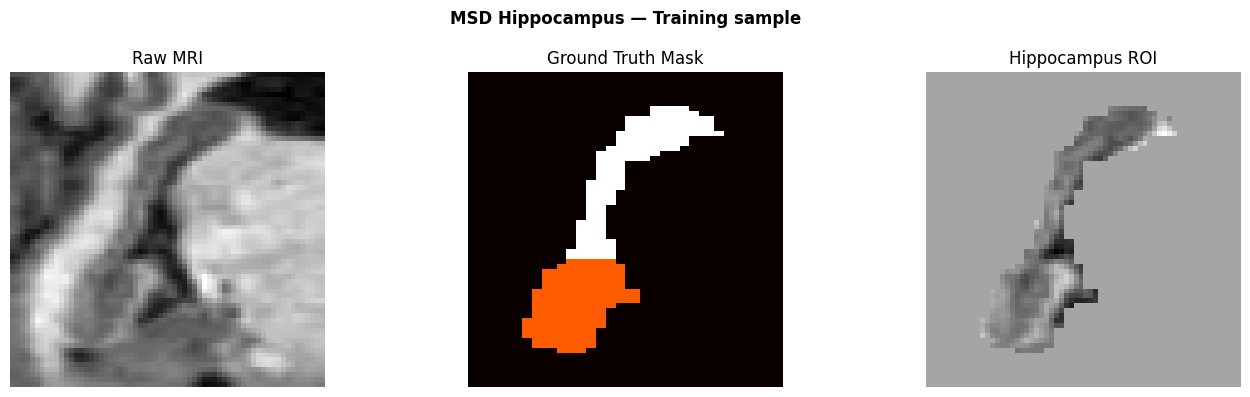

In [5]:
img_np = img[0].numpy(); lab_np = lab.numpy(); mid = img_np.shape[0]//2
fig, axes = plt.subplots(1,3,figsize=(14,4))
fig.suptitle('MSD Hippocampus — Training sample', fontweight='bold')
for ax,data,title,cm in zip(axes,
    [img_np[mid], lab_np[mid], img_np[mid]*(lab_np[mid]>0)],
    ['Raw MRI','Ground Truth Mask','Hippocampus ROI'],
    ['gray','hot','gray']):
    ax.imshow(data, cmap=cm); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()

## Module 4a — UNet Segmentation (MSD Training)

In [6]:
class DiceLoss(nn.Module):
    """Soft Dice loss for 3D multi-class segmentation."""
    def __init__(self, num_classes=3, smooth=1e-5):
        super().__init__()
        self.num_classes = num_classes
        self.smooth      = smooth

    def forward(self, logits, targets):
        probs          = F.softmax(logits, dim=1)
        targets_onehot = F.one_hot(
            targets.clamp(0, self.num_classes-1),
            self.num_classes).permute(0,4,1,2,3).float()
        dims  = (0,2,3,4)
        inter = (probs * targets_onehot).sum(dim=dims)
        union = probs.sum(dim=dims) + targets_onehot.sum(dim=dims)
        dice  = (2*inter + self.smooth) / (union + self.smooth)
        return 1 - dice.mean()


def dice_score(pred, target):
    """Correct Dice — always in [0,1]. Guards zero denominator."""
    inter = ((pred > 0) & (target > 0)).sum().float()
    denom = (pred > 0).sum().float() + (target > 0).sum().float()
    if denom == 0:
        return 1.0
    return (2 * inter / denom).item()


seg_model = UNet(
    spatial_dims  = 3,
    in_channels   = 1,
    out_channels  = 3,
    channels      = (16,32,64,128,256),
    strides       = (2,2,2,2),
    num_res_units = 2,
    dropout       = 0.1,
).to(device)

ce_loss   = nn.CrossEntropyLoss()
dice_loss = DiceLoss(num_classes=3)
seg_opt   = torch.optim.AdamW(seg_model.parameters(), lr=2e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(seg_opt, T_max=20)
print(f'Seg model params: {sum(p.numel() for p in seg_model.parameters()):,}')

Seg model params: 4,807,482


In [7]:
SEG_EPOCHS    = 20
seg_history   = {'train_loss':[], 'train_dice':[], 'val_loss':[], 'val_dice':[]}
best_seg_dice = 0.0

print(f"{'Epoch':>6}  {'TrLoss':>8}  {'TrDice':>8}  {'VlLoss':>8}  {'VlDice':>8}")
print('─'*50)

for epoch in range(SEG_EPOCHS):
    seg_model.train(); t_loss=t_dice=0
    for imgs, labs in msd_loader:
        imgs, labs = imgs.to(device), labs.to(device)
        seg_opt.zero_grad()
        logits = seg_model(imgs)
        loss   = ce_loss(logits, labs) + dice_loss(logits, labs)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(seg_model.parameters(), 1.0)
        seg_opt.step()
        t_loss += loss.item()
        t_dice += dice_score(torch.argmax(logits,dim=1), labs)

    seg_model.eval(); v_loss=v_dice=0
    with torch.no_grad():
        for imgs, labs in msd_val_loader:
            imgs, labs = imgs.to(device), labs.to(device)
            logits = seg_model(imgs)
            loss   = ce_loss(logits, labs) + dice_loss(logits, labs)
            v_loss += loss.item()
            v_dice += dice_score(torch.argmax(logits,dim=1), labs)

    scheduler.step()
    nt, nv = len(msd_loader), len(msd_val_loader)
    seg_history['train_loss'].append(t_loss/nt)
    seg_history['train_dice'].append(t_dice/nt)
    seg_history['val_loss'].append(v_loss/nv)
    seg_history['val_dice'].append(v_dice/nv)

    flag = ' ✔' if v_dice/nv > best_seg_dice else ''
    if v_dice/nv > best_seg_dice:
        best_seg_dice = v_dice/nv
        torch.save(seg_model.state_dict(), '/content/hippocampus_unet.pth')
    print(f"{epoch+1:>6}  {t_loss/nt:>8.4f}  {t_dice/nt:>8.4f}  {v_loss/nv:>8.4f}  {v_dice/nv:>8.4f}{flag}")

print(f'\n✔ Best Val Dice: {best_seg_dice:.4f}  →  /content/hippocampus_unet.pth')

 Epoch    TrLoss    TrDice    VlLoss    VlDice
──────────────────────────────────────────────────
     1    1.7696    0.2125    1.4855    0.3747 ✔
     2    1.3525    0.4845    1.1320    0.7325 ✔
     3    0.9972    0.6742    0.7975    0.8034 ✔
     4    0.7357    0.7881    0.5983    0.8318 ✔
     5    0.5785    0.8328    0.4779    0.8465 ✔
     6    0.4731    0.8468    0.3922    0.8513 ✔
     7    0.3972    0.8541    0.3364    0.8555 ✔
     8    0.3439    0.8613    0.2946    0.8633 ✔
     9    0.3055    0.8663    0.2693    0.8666 ✔
    10    0.2770    0.8711    0.2498    0.8682 ✔
    11    0.2534    0.8758    0.2335    0.8715 ✔
    12    0.2356    0.8799    0.2255    0.8744 ✔
    13    0.2230    0.8818    0.2168    0.8731
    14    0.2123    0.8853    0.2136    0.8734
    15    0.2040    0.8877    0.2078    0.8745 ✔
    16    0.1988    0.8890    0.2060    0.8746 ✔
    17    0.1950    0.8901    0.2050    0.8744
    18    0.1919    0.8914    0.2037    0.8748 ✔
    19    0.1907    0.8920

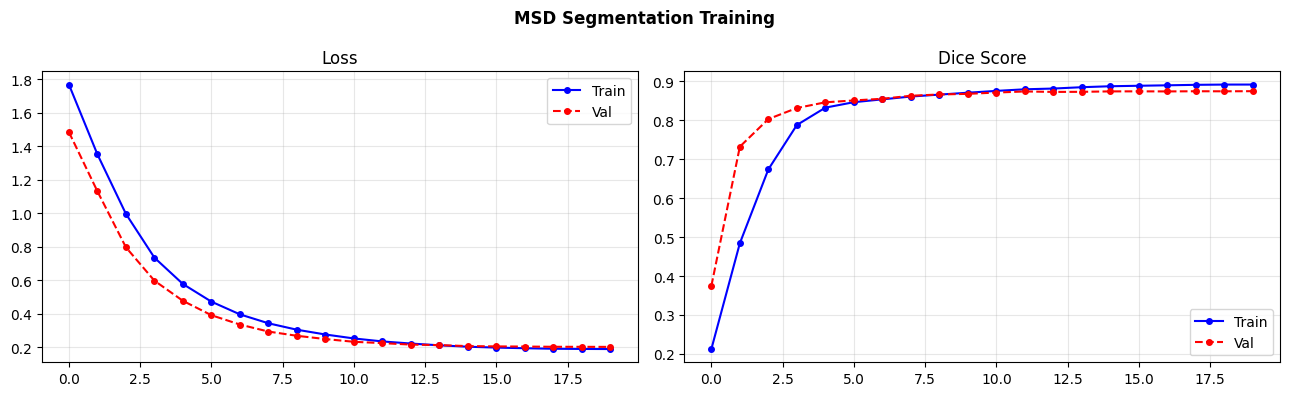

In [8]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(13,4))
fig.suptitle('MSD Segmentation Training', fontweight='bold')
ax1.plot(seg_history['train_loss'],'b-o',ms=4,label='Train')
ax1.plot(seg_history['val_loss'],  'r--o',ms=4,label='Val')
ax1.set_title('Loss'); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(seg_history['train_dice'],'b-o',ms=4,label='Train')
ax2.plot(seg_history['val_dice'],  'r--o',ms=4,label='Val')
ax2.set_title('Dice Score'); ax2.legend(); ax2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Test Set Evaluation — MSD

Test → Samples:39  Mean Dice:0.8663
Min:0.7853  Max:0.8945


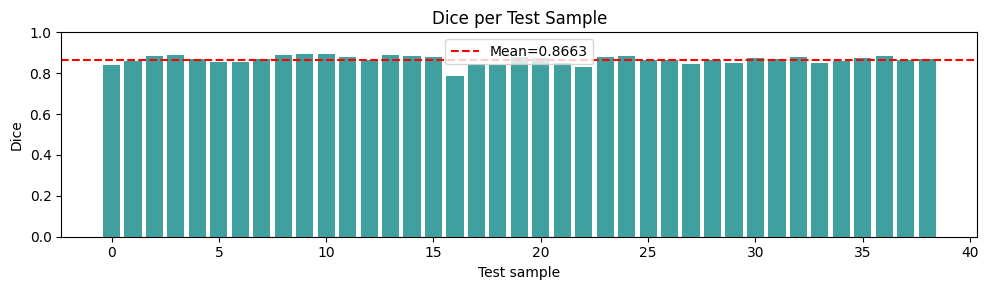

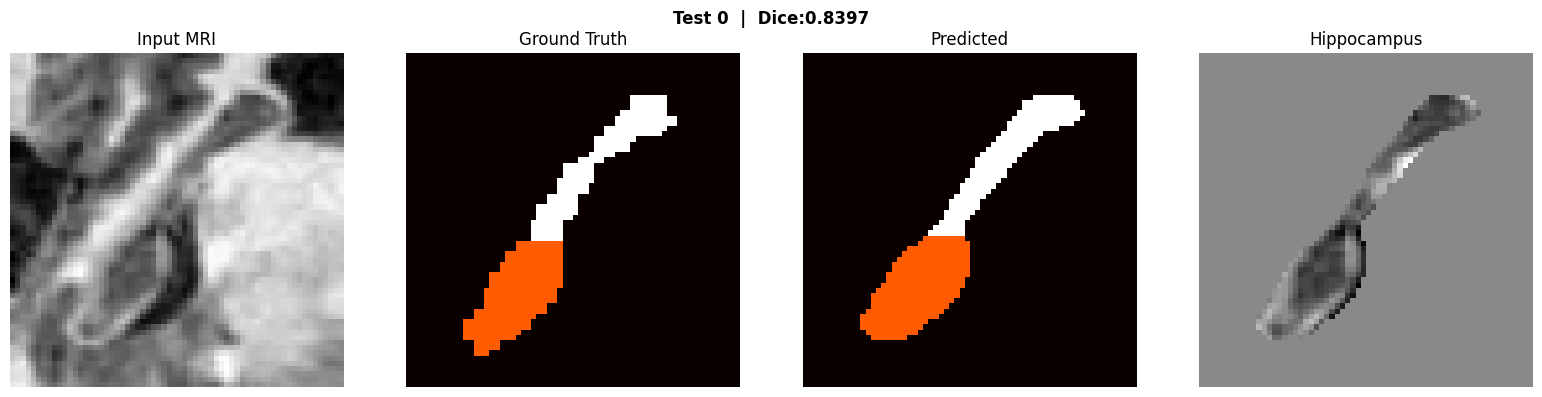

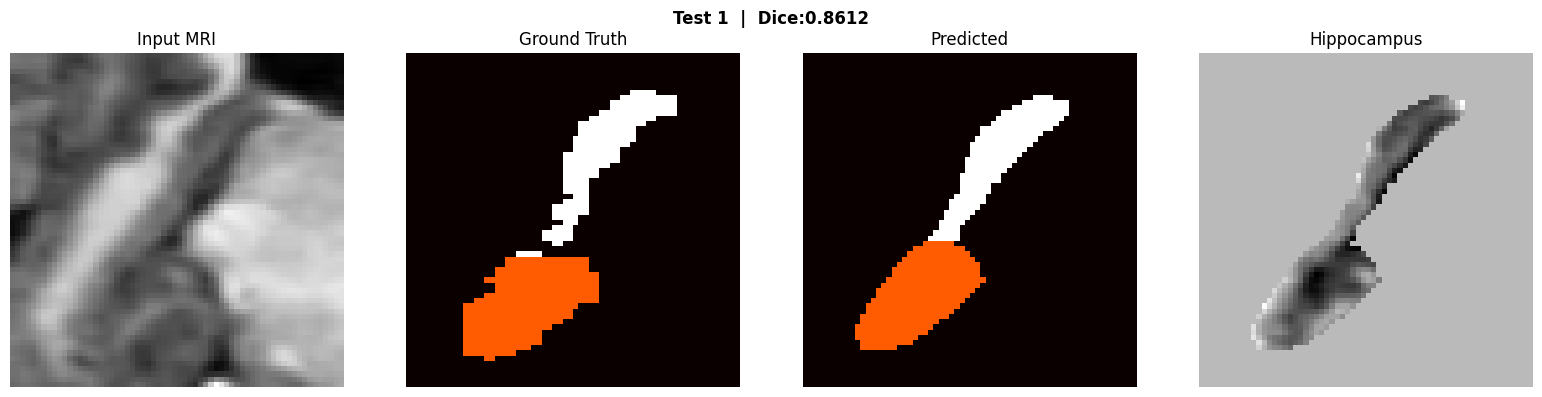

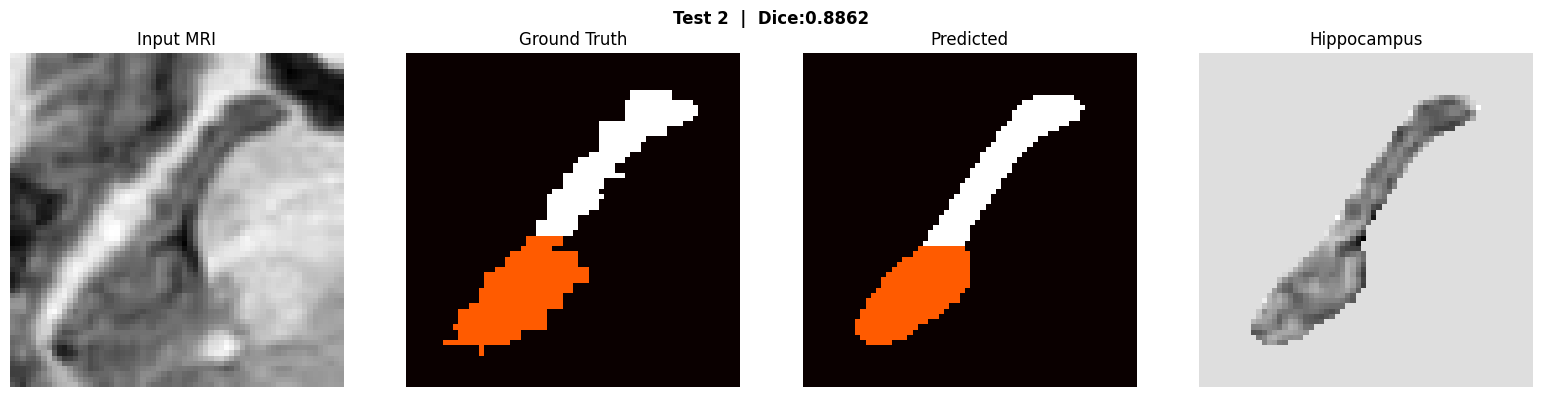

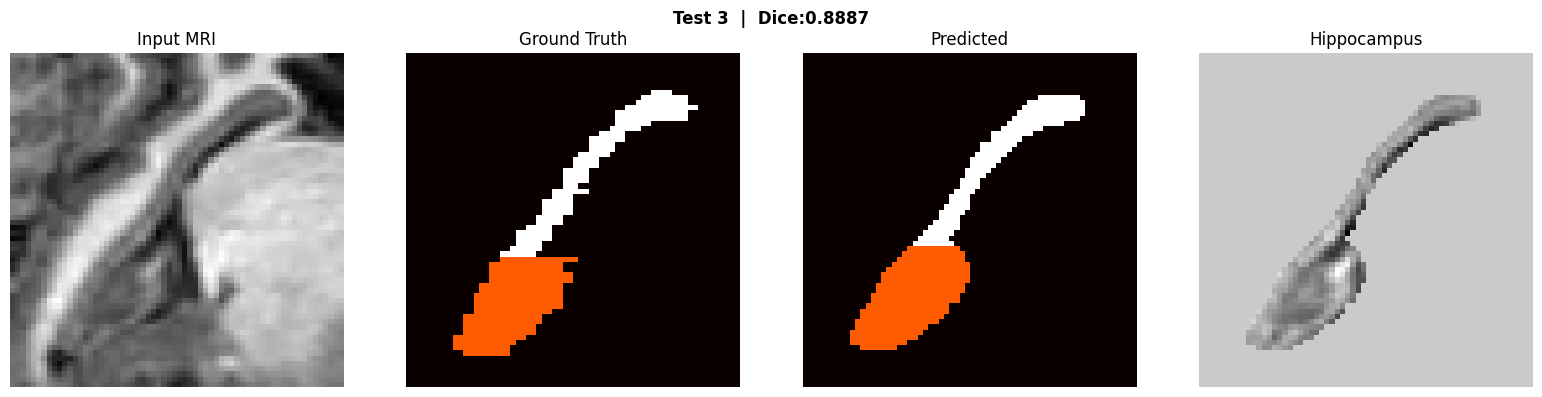

In [9]:
seg_model.load_state_dict(torch.load('/content/hippocampus_unet.pth', map_location=device))
seg_model.eval()
all_dice = []
with torch.no_grad():
    for img_b, lab_b in msd_test_loader:
        img_b, lab_b = img_b.to(device), lab_b.to(device)
        pred = torch.argmax(seg_model(img_b), dim=1)
        all_dice.append(dice_score(pred, lab_b))

mean_dice = sum(all_dice)/len(all_dice)
print(f'Test → Samples:{len(all_dice)}  Mean Dice:{mean_dice:.4f}')
print(f'Min:{min(all_dice):.4f}  Max:{max(all_dice):.4f}')

plt.figure(figsize=(10,3))
plt.bar(range(len(all_dice)), all_dice, color='teal', alpha=0.75)
plt.axhline(mean_dice, color='red', ls='--', label=f'Mean={mean_dice:.4f}')
plt.xlabel('Test sample'); plt.ylabel('Dice'); plt.ylim(0,1)
plt.title('Dice per Test Sample'); plt.legend(); plt.tight_layout(); plt.show()

for si in range(min(4, len(test_msd))):
    img_t, lab_t = test_msd[si]
    with torch.no_grad():
        pred = torch.argmax(seg_model(img_t.unsqueeze(0).to(device)),dim=1).squeeze().cpu()
    mid = img_t.shape[1]//2; d = dice_score(pred, lab_t)
    fig, axes = plt.subplots(1,4,figsize=(16,4))
    fig.suptitle(f'Test {si}  |  Dice:{d:.4f}', fontweight='bold')
    for ax,data,title,cm in zip(axes,
        [img_t[0].numpy()[mid], lab_t.numpy()[mid],
         pred.numpy()[mid],     img_t[0].numpy()[mid]*(pred.numpy()[mid]>0)],
        ['Input MRI','Ground Truth','Predicted','Hippocampus'],['gray','hot','hot','gray']):
        ax.imshow(data,cmap=cm); ax.set_title(title); ax.axis('off')
    plt.tight_layout(); plt.show()

## UNet Fine-Tuning on OASIS (Strategy 1 — Freeze Encoder)

In [10]:
# Reload best MSD weights
seg_model.load_state_dict(torch.load('/content/hippocampus_unet.pth', map_location=device))

# Freeze everything first
for p in seg_model.parameters():
    p.requires_grad = False

# Check actual parameter names
print("Sample parameter names:")
for name, _ in list(seg_model.named_parameters())[:10]:
    print(" ", name)

Sample parameter names:
  model.0.conv.unit0.conv.weight
  model.0.conv.unit0.conv.bias
  model.0.conv.unit0.adn.A.weight
  model.0.conv.unit1.conv.weight
  model.0.conv.unit1.conv.bias
  model.0.conv.unit1.adn.A.weight
  model.0.residual.weight
  model.0.residual.bias
  model.1.submodule.0.conv.unit0.conv.weight
  model.1.submodule.0.conv.unit0.conv.bias


In [11]:
trainable = sum(p.numel() for p in seg_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in seg_model.parameters())

In [12]:
# Reload best MSD weights
seg_model.load_state_dict(torch.load('/content/hippocampus_unet.pth', map_location=device))

# Freeze everything
for p in seg_model.parameters():
    p.requires_grad = True

# Unfreeze last 30% of layers by position
all_params = list(seg_model.parameters())
n_unfreeze  = max(1, len(all_params) // 3)
for p in all_params[-n_unfreeze:]:
    p.requires_grad = True

trainable = sum(p.numel() for p in seg_model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in seg_model.parameters())
print(f'Trainable: {trainable:,} / {total:,}  ({100*trainable/total:.1f}%)')

Trainable: 4,807,482 / 4,807,482  (100.0%)


## Module 1 — OASIS Dataset + Labels

In [14]:
OASIS_EXCEL = '/content/drive/MyDrive/oasis_cross-sectional-5708aa0a98d82080 (1).xlsx'
df_oasis    = pd.read_excel(OASIS_EXCEL)

CDR_MAP     = {0.0:0, 0.5:1, 1.0:2, 2.0:3}
CLASS_NAMES = {0:'Normal (CDR 0)', 1:'Very Mild (CDR 0.5)',
               2:'Mild (CDR 1)',    3:'Moderate (CDR 2+)'}

def get_label(mri_id):
    row = df_oasis[df_oasis['ID'] == mri_id]
    if len(row)==0: return None
    cdr = row['CDR'].values[0]
    if pd.isna(cdr): return None
    return CDR_MAP.get(float(cdr), 3 if float(cdr)>=2 else None)

print('Excel loaded:', df_oasis.shape)
print('CDR distribution:', dict(Counter(df_oasis['CDR'].dropna().tolist())))

Excel loaded: (436, 12)
CDR distribution: {0.0: 135, 0.5: 70, 1.0: 62, 2.0: 2}


## Module 2 — OASIS Preprocessing

In [15]:
# ─── Localized hippocampus segmentation ──────────────────────────────────
# BOX_L / BOX_R were found empirically: a sliding-window search using the
# ORIGINAL MSD-pretrained seg_model weights, scored by total foreground
# probability, restricted to windows that are >=60% real brain tissue
# (to reject degenerate all-background windows). Both boxes were then
# visually confirmed to reproduce at a consistent relative anatomical
# location across multiple subjects (OAS1_0001-0004) in the same T88
# atlas-registered space. This is a fixed, DATASET-WIDE crop -- it only
# works because every OASIS T88 scan shares the same 176x208x176 grid.
BOX_SIZE = (40, 56, 40)
BOX_L    = (18, 48, 26)
BOX_R    = (114, 40, 26)


def load_mri_and_bbox(path, target_size=(64,64,64)):
    """
    Loads a scan, returns:
      mri        - z-scored, cropped-to-nonzero, resized-to-target_size tensor
                   (same as the original load_mri -- used as ADModel_M5 input)
      img_raw    - the RAW (un-normalized) full volume, needed so the fixed
                   BOX_L/BOX_R windows can be cropped at native resolution
      bbox       - the nonzero crop bounds (x0,x1,y0,y1,z0,z1) applied to
                   img_raw to get `mri` -- reused so the hippocampus mask
                   is cropped/resized identically and stays spatially
                   aligned with `mri`
    """
    img = nib.load(path).get_fdata()
    if img.ndim == 4: img = img[...,0]
    nz = np.nonzero(img)
    if len(nz[0]) > 0:
        x0, x1 = nz[0].min(), nz[0].max()+1
        y0, y1 = nz[1].min(), nz[1].max()+1
        z0, z1 = nz[2].min(), nz[2].max()+1
    else:
        x0,x1,y0,y1,z0,z1 = 0,img.shape[0],0,img.shape[1],0,img.shape[2]

    img_cropped = img[x0:x1, y0:y1, z0:z1]
    img_norm    = (img_cropped - img_cropped.mean()) / (img_cropped.std() + 1e-8)
    img_norm    = np.nan_to_num(img_norm)
    t = torch.tensor(img_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    t = F.interpolate(t, size=target_size, mode='trilinear', align_corners=False)
    return t.squeeze(0), img, (x0,x1,y0,y1,z0,z1)


def segment_hippocampus_localized(img_raw, bbox, target_size=(64,64,64)):
    """
    Runs seg_model on the two FIXED (left/right) native-resolution windows
    (matching MSD's ~40x56x40 training scale), places each prediction back
    into full-brain-volume space, then applies the SAME nonzero-crop +
    resize as load_mri_and_bbox used for the MRI channel -- so the mask
    stays voxel-aligned with `mri` in the final 64^3 space.
    """
    full_mask = np.zeros_like(img_raw, dtype=np.float32)
    valid = img_raw[img_raw != 0]
    brain_mean = valid.mean() if len(valid) else 0.0
    brain_std  = valid.std() + 1e-8 if len(valid) else 1.0

    for (x0, y0, z0) in [BOX_L, BOX_R]:
        wx, wy, wz = BOX_SIZE
        patch = img_raw[x0:x0+wx, y0:y0+wy, z0:z0+wz]
        if patch.shape != (wx, wy, wz):
            continue
        patch_norm = (patch - brain_mean) / brain_std
        patch_norm[patch == 0] = 0
        t = torch.tensor(patch_norm, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
        t_resized = F.interpolate(t, size=target_size, mode='trilinear', align_corners=False).to(device)
        with torch.no_grad():
            pred = torch.argmax(seg_model(t_resized), dim=1).squeeze(0).cpu().numpy()
        pred_bin = (pred > 0).astype(np.float32)
        pred_t = torch.tensor(pred_bin).unsqueeze(0).unsqueeze(0)
        pred_native = F.interpolate(pred_t, size=(wx, wy, wz), mode='nearest').squeeze().numpy()
        full_mask[x0:x0+wx, y0:y0+wy, z0:z0+wz] = np.maximum(
            full_mask[x0:x0+wx, y0:y0+wy, z0:z0+wz], pred_native)

    bx0, bx1, by0, by1, bz0, bz1 = bbox
    mask_cropped = full_mask[bx0:bx1, by0:by1, bz0:bz1]
    mt = torch.tensor(mask_cropped, dtype=torch.float32).unsqueeze(0).unsqueeze(0)
    mt = F.interpolate(mt, size=target_size, mode='nearest')
    return mt.squeeze(0)


In [16]:
import glob
class OASISDataset(Dataset):
    def __init__(self, root_dirs):
        if isinstance(root_dirs, str):
            root_dirs = [root_dirs]

        paths_and_labels = []
        for root_dir in root_dirs:
            for subject in sorted(os.listdir(root_dir)):
                label = get_label(subject)
                if label is None: continue
                # Use ONLY the atlas-registered, skull-stripped T88 file --
                # avoids picking up SUBJ_111 (native space) or the
                # non-masked T88 gfc file, which would mix different
                # coordinate spaces / preprocessing under one label.
                t88_dir = os.path.join(root_dir, subject, 'PROCESSED', 'MPRAGE', 'T88_111')
                # Filename encodes acquisition count (n1, n2, n3, n4...) which
                # varies per subject -- glob for any count, don't hardcode n4.
                matches = sorted(glob.glob(os.path.join(
                    t88_dir, f'{subject}_mpr_n*_anon_111_t88_masked_gfc.img')))
                if matches:
                    paths_and_labels.append((matches[0], label, subject))

        print(f'Found {len(paths_and_labels)} scans across {len(root_dirs)} disc(s) '
              f'(T88 atlas-registered, skull-stripped only). Pre-computing masks...')
        self.mris=[]; self.hippos=[]; self.labels=[]; self.tabular=[]

        # --- Extract and z-score normalise tabular features ---
        TAB_COLS = ['Age', 'Educ', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']
        tab_raw = []
        for path, label, subject in paths_and_labels:
            row = df_oasis[df_oasis['ID'] == subject]
            feats = []
            for col in TAB_COLS:
                if len(row) > 0 and col in row.columns:
                    val = row[col].values[0]
                    feats.append(float(val) if not pd.isna(val) else 0.0)
                else:
                    feats.append(0.0)
            tab_raw.append(feats)
        tab_arr = np.array(tab_raw, dtype=np.float32)
        tab_mean = tab_arr.mean(axis=0)
        tab_std  = tab_arr.std(axis=0) + 1e-8
        tab_norm = (tab_arr - tab_mean) / tab_std

        for i, (path, label, subject) in enumerate(paths_and_labels):
            mri, img_raw, bbox = load_mri_and_bbox(path)
            mask = segment_hippocampus_localized(img_raw, bbox)
            self.mris.append(mri)
            self.hippos.append(mri * mask)
            self.labels.append(label)
            self.tabular.append(torch.tensor(tab_norm[i], dtype=torch.float32))
            if (i+1) % 10 == 0 or (i+1) == len(paths_and_labels):
                print(f'  {i+1}/{len(paths_and_labels)}', end='\r')
        print()
        counts = Counter(self.labels)
        print(f'OASIS ready: {len(self.labels)} samples')
        for k, v in sorted(counts.items()):
            print(f'  Class {k} - {CLASS_NAMES[k]}: {v} samples')

    def __len__(self): return len(self.mris)

    def __getitem__(self, i):
        return self.mris[i], self.hippos[i], self.tabular[i], \
               torch.tensor(self.labels[i], dtype=torch.long)


## FIX 1 — Load Full Dataset (No Pre-Split)
Stratified k-fold will handle all splitting. No `random_split` here.

## Sanity check — confirm the localized mask actually finds signal before the full (slow) rebuild
Uses the ORIGINAL MSD-pretrained `seg_model` weights (the ones BOX_L/BOX_R were validated against). If this prints a non-zero foreground fraction, it's safe to run the full `OASISDataset` build below.


In [17]:
# Make sure we're using the ORIGINAL MSD weights (not any leftover fine-tuned ones)
seg_model.load_state_dict(torch.load('/content/hippocampus_unet.pth', map_location=device))
seg_model.eval()

_sample_path = None
for _root in ['/content/drive/MyDrive/oasis_cross-sectional_disc1/disc1',
              '/content/drive/MyDrive/oasis_cross-sectional_disc2/disc2']:
    if not os.path.isdir(_root): continue
    for _subj in sorted(os.listdir(_root)):
        _fp = os.path.join(_root, _subj, 'PROCESSED', 'MPRAGE', 'T88_111',
                            f'{_subj}_mpr_n4_anon_111_t88_masked_gfc.img')
        if os.path.isfile(_fp):
            _sample_path = _fp
            break
    if _sample_path: break

mri_t, raw_t, bbox_t = load_mri_and_bbox(_sample_path)
mask_t = segment_hippocampus_localized(raw_t, bbox_t)
fg_frac = (mask_t != 0).float().mean().item()
print(f'Sample: {_sample_path}')
print(f'Foreground voxel fraction (aligned, 64^3 space): {fg_frac:.4f}')
if fg_frac > 0:
    print('Non-zero signal found -- safe to proceed with the full dataset build below.')
else:
    print('WARNING: still zero. Do not proceed to the full rebuild -- re-check BOX_L/BOX_R.')


Sample: /content/drive/MyDrive/oasis_cross-sectional_disc1/disc1/OAS1_0001_MR1/PROCESSED/MPRAGE/T88_111/OAS1_0001_MR1_mpr_n4_anon_111_t88_masked_gfc.img
Foreground voxel fraction (aligned, 64^3 space): 0.0034
Non-zero signal found -- safe to proceed with the full dataset build below.


In [18]:
import os

img_path = "/content/drive/MyDrive/oasis_cross-sectional_disc1/disc1/OAS1_0034_MR1/PROCESSED/MPRAGE/T88_111/OAS1_0034_MR1_mpr_n3_anon_111_t88_masked_gfc.img"

folder = os.path.dirname(img_path)

print("Files in folder:")
for f in os.listdir(folder):
    print(f)

Files in folder:
OAS1_0034_MR1_mpr_n3_anon_111_t88_gfc.img
OAS1_0034_MR1_mpr_n3_anon_111_t88_masked_gfc.img
OAS1_0034_MR1_mpr_n3_anon_111_t88_gfc.hdr
OAS1_0034_MR1_mpr_n3_anon_111_t88_gfc_cor_110.gif
OAS1_0034_MR1_mpr_n3_anon_111_t88_gfc_tra_90.gif
OAS1_0034_MR1_mpr_n3_anon_111_t88_masked_gfc.hdr
OAS1_0034_MR1_mpr_n3_anon_111_t88_masked_gfc_tra_90.gif
OAS1_0034_MR1_mpr_n3_anon_111_t88_gfc_sag_95.gif
t4_files


In [19]:
OASIS_PATHS = [
    '/content/drive/MyDrive/oasis_cross-sectional_disc1/disc1',
    '/content/drive/MyDrive/oasis_cross-sectional_disc2/disc2',
    '/content/drive/MyDrive/oasis_cross-sectional_disc3/disc3',

]
full_dataset = OASISDataset(OASIS_PATHS)


Found 88 scans across 3 disc(s) (T88 atlas-registered, skull-stripped only). Pre-computing masks...
  88/88
OASIS ready: 88 samples
  Class 0 - Normal (CDR 0): 36 samples
  Class 1 - Very Mild (CDR 0.5): 17 samples
  Class 2 - Mild (CDR 1): 35 samples


In [20]:
# OASIS fine-tuning of seg_model is intentionally skipped.
# seg_model keeps its original MSD-pretrained weights throughout --
# no further training happens here. Nothing downstream depends on
# '/content/hippocampus_unet_finetuned.pth' being created.
print('Skipping OASIS UNet fine-tuning -- using MSD-pretrained seg_model as-is.')


Skipping OASIS UNet fine-tuning -- using MSD-pretrained seg_model as-is.


## UNet Fine-Tune Training on OASIS

In [21]:
# (Fine-tune history plot skipped -- fine-tuning step is disabled above.)


## Module 3 — Shared 3D CNN Encoder

## Module 3 — Shared 3D CNN Encoder (FIX 3: Reduced Complexity, Higher Dropout)

In [22]:
class Encoder(nn.Module):
    def __init__(self, dropout=0.45, in_channels=1):   # add in_channels param
        super().__init__()
        self.block1 = nn.Sequential(
            nn.Conv3d(in_channels, 16, 3, padding=1), nn.BatchNorm3d(16),
            nn.ReLU(inplace=True), nn.Dropout3d(dropout))
        self.block2 = nn.Sequential(
            nn.Conv3d(16, 48, 3, padding=1), nn.BatchNorm3d(48),  # FIX 3: 64->48
            nn.ReLU(inplace=True), nn.Dropout3d(dropout))
        self.block3 = nn.Sequential(
            nn.Conv3d(48, 96, 3, padding=1), nn.BatchNorm3d(96),  # FIX 3: 128->96
            nn.ReLU(inplace=True))
        self.pool = nn.MaxPool3d(2)

    def forward(self, x):
        x = self.pool(self.block1(x))   # [B,  16, 32, 32, 32]
        x = self.pool(self.block2(x))   # [B,  48, 16, 16, 16]
        x = self.pool(self.block3(x))   # [B,  96,  8,  8,  8]
        return x

_enc = Encoder().to(device)
_x   = torch.zeros(1,1,64,64,64).to(device)
out  = _enc(_x)
print(f'Encoder output: {out.shape}')  # [1,96,8,8,8]
print(f'Encoder params: {sum(p.numel() for p in _enc.parameters()):,}  (smaller = less overfit)')
del _enc, _x, out


Encoder output: torch.Size([1, 96, 8, 8, 8])
Encoder params: 146,064  (smaller = less overfit)


## Module 4b — Cross-Scale Swin Transformer (REAL window-based attention)

In [23]:
class PatchEmbed3D(nn.Module):
    def __init__(self, window_size=2):
        super().__init__()
        self.ws = window_size

    def forward(self, x):
        B, C, D, H, W = x.shape
        ws = self.ws
        x = x.view(B, C, D//ws, ws, H//ws, ws, W//ws, ws)
        x = x.permute(0, 2, 4, 6, 3, 5, 7, 1)
        nD, nH, nW = D//ws, H//ws, W//ws
        x = x.reshape(B*nD*nH*nW, ws*ws*ws, C)
        return x, (B, nD, nH, nW)


class SwinBlock3D(nn.Module):
    def __init__(self, dim=96, num_heads=4, mlp_ratio=2.0, dropout=0.45):  # FIX 3: mlp_ratio 4->2
        super().__init__()
        self.norm1  = nn.LayerNorm(dim)
        self.norm2  = nn.LayerNorm(dim)
        self.w_attn = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        mlp_dim     = int(dim * mlp_ratio)
        self.ffn    = nn.Sequential(
            nn.Linear(dim, mlp_dim), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(mlp_dim, dim), nn.Dropout(dropout))

    def forward(self, x):
        n = self.norm1(x)
        a, _ = self.w_attn(n, n, n)
        x = x + a
        x = x + self.ffn(self.norm2(x))
        return x


class CrossScaleSwinTransformer3D(nn.Module):
    """FIX 3: dim reduced to 96 to match smaller Encoder output channels."""
    def __init__(self, in_channels=96, dim=96, num_heads=4, dropout=0.45):
        super().__init__()
        self.proj         = nn.Conv3d(in_channels, dim, 1)
        self.patch_fine   = PatchEmbed3D(window_size=2)
        self.swin_fine    = nn.ModuleList([SwinBlock3D(dim, num_heads, dropout=dropout) for _ in range(2)])
        self.patch_coarse = PatchEmbed3D(window_size=4)
        self.swin_coarse  = nn.ModuleList([SwinBlock3D(dim, num_heads, dropout=dropout) for _ in range(2)])
        self.cross_attn   = nn.MultiheadAttention(dim, num_heads, dropout=dropout, batch_first=True)
        self.cross_norm   = nn.LayerNorm(dim)
        self.out_norm     = nn.LayerNorm(dim)
        self.out_proj     = nn.Linear(dim, dim)

    def forward(self, feat):
        B = feat.size(0)
        x = self.proj(feat)
        fine_tokens, (_, nD, nH, nW) = self.patch_fine(x)
        for blk in self.swin_fine:
            fine_tokens = blk(fine_tokens)
        fine_global = fine_tokens.mean(dim=1, keepdim=True).view(B, nD*nH*nW, -1)
        coarse_tokens, (_, cD, cH, cW) = self.patch_coarse(x)
        for blk in self.swin_coarse:
            coarse_tokens = blk(coarse_tokens)
        coarse_global = coarse_tokens.mean(dim=1).view(B, cD*cH*cW, -1)
        cross_out, _ = self.cross_attn(fine_global, coarse_global, coarse_global)
        fused = self.cross_norm(fine_global + cross_out)
        global_ctx = self.out_norm(fused).mean(dim=1)
        return self.out_proj(global_ctx)

_tr  = CrossScaleSwinTransformer3D().to(device)
_x   = torch.zeros(2, 96, 8, 8, 8).to(device)
_out = _tr(_x)
print(f'CrossScaleSwinTransformer3D output: {_out.shape}')  # [2, 96]
del _tr, _x, _out


CrossScaleSwinTransformer3D output: torch.Size([2, 96])


## Module 5 — Attention Fusion

In [24]:
class AttentionFusion(nn.Module):
    """FIX 3: dim=96 to match reduced encoder."""
    def __init__(self, dim=96):  # was 128
        super().__init__()
        self.gate = nn.Sequential(
            nn.Linear(dim*2, dim), nn.ReLU(inplace=True),
            nn.Linear(dim, dim),   nn.Sigmoid())

    def forward(self, global_feat, local_feat):
        g = self.gate(torch.cat([global_feat, local_feat], dim=1))
        return g * global_feat + (1-g) * local_feat


## Full Model — ADModel_M5 (FIX 3: Reduced Complexity + Higher Dropout)

In [25]:
class ADModel_M5(nn.Module):
    """
    FIX 3: Reduced complexity throughout:
      - Encoder: 16→48→96 filters (was 32→64→128)
      - Dropout: 0.45 (was 0.1/0.3)
      - Classifier: 192→64→3 (unchanged)
      - mlp_ratio in Swin: 2.0 (was 4.0)
    """
    def __init__(self):
        super().__init__()
        DROPOUT = 0.45  # FIX 3: centralised dropout constant
        self.shared_encoder = Encoder(dropout=DROPOUT, in_channels=2)
        self.seg_decoder = nn.Sequential(
            nn.ConvTranspose3d(96, 48, 2, stride=2),
            nn.BatchNorm3d(48), nn.ReLU(inplace=True),
            nn.ConvTranspose3d(48, 24, 2, stride=2),
            nn.BatchNorm3d(24), nn.ReLU(inplace=True),
            nn.ConvTranspose3d(24, 12, 2, stride=2),
            nn.BatchNorm3d(12), nn.ReLU(inplace=True),
            nn.Conv3d(12, 3, 1))
        self.seg_pool = nn.Sequential(
            nn.AdaptiveAvgPool3d((4,4,4)),
            nn.Flatten(),
            nn.Linear(3*4*4*4, 96),
            nn.ReLU(inplace=True))
        self.swin_transformer = CrossScaleSwinTransformer3D(
            in_channels=96, dim=96, num_heads=4, dropout=DROPOUT)
        self.fusion = AttentionFusion(dim=96)
        self.tab_encoder = nn.Sequential(
            nn.Linear(7, 24), nn.ReLU(), nn.Dropout(DROPOUT),
            nn.Linear(24, 48), nn.ReLU()
        )
        # Classifier: 96 (MRI) + 48 (tabular) = 144
        self.classifier = nn.Sequential(
            nn.LayerNorm(96 + 48),
            nn.Linear(96 + 48, 48),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(48, 3)
        )

    def forward(self, x, hippo, tabular):
        x_in = torch.cat([x, hippo], dim=1)   # [B, 2, 64, 64, 64]
        shared_feat = self.shared_encoder(x_in)        # [B, 96, 8, 8, 8]
        seg_logits  = self.seg_decoder(shared_feat)   # [B, 3, 64, 64, 64]
        local_feat  = self.seg_pool(seg_logits)       # [B, 96]
        global_feat = self.swin_transformer(shared_feat)  # [B, 96]
        fused       = self.fusion(global_feat, local_feat)  # [B, 96]
        tab_feat    = self.tab_encoder(tabular)        # [B, 48]
        fused_all   = torch.cat([fused, tab_feat], dim=1)   # [B, 144]
        cls_logits  = self.classifier(fused_all)       # [B, 3]
        return fused, seg_logits, cls_logits


model = ADModel_M5().to(device)
total = sum(p.numel() for p in model.parameters())
print(f'ADModel_M5 total params: {total:,}')
print(f'  Encoder      : {sum(p.numel() for p in model.shared_encoder.parameters()):,}')
print(f'  Seg Decoder  : {sum(p.numel() for p in model.seg_decoder.parameters()):,}')
print(f'  Swin (M4b)   : {sum(p.numel() for p in model.swin_transformer.parameters()):,}')
print(f'  Fusion (M5)  : {sum(p.numel() for p in model.fusion.parameters()):,}')
print(f'  Tab Encoder  : {sum(p.numel() for p in model.tab_encoder.parameters()):,}')
print(f'  Classifier   : {sum(p.numel() for p in model.classifier.parameters()):,}')

with torch.no_grad():
    _x     = torch.zeros(2, 1, 64, 64, 64).to(device)
    _hippo = torch.zeros(2, 1, 64, 64, 64).to(device)
    _tab   = torch.zeros(2, 7).to(device)   # 6 -> 7, now that MMSE is added
    _f, _s, _c = model(_x, _hippo, _tab)
    print(f'Fused:{_f.shape} | Seg:{_s.shape} | Cls:{_c.shape}')
del _x, _hippo, _tab, _f, _s, _c

ADModel_M5 total params: 605,718
  Encoder      : 146,496
  Seg Decoder  : 48,675
  Swin (M4b)   : 355,392
  Fusion (M5)  : 27,840
  Tab Encoder  : 1,392
  Classifier   : 7,395
Fused:torch.Size([2, 96]) | Seg:torch.Size([2, 3, 64, 64, 64]) | Cls:torch.Size([2, 3])


## FIX 2 — Correct Class Weights via `compute_class_weight` + Focal Loss

In [26]:
# ─── FIX 2: Class Weights ──────────────────────────────────────────────
# Merge label 3 (Moderate) into label 2 (Mild) since Moderate=0 samples
labels_3cls = np.array([min(l, 2) for l in full_dataset.labels])

unique_cls = np.unique(labels_3cls)
cls_weights_np = compute_class_weight(
    class_weight='balanced',
    classes=unique_cls,
    y=labels_3cls
)
# Pad to 3 classes (in case Mild has 0 samples in a fold)
weights_m5 = torch.ones(3, dtype=torch.float32)
for idx, cls in enumerate(unique_cls):
    weights_m5[cls] = cls_weights_np[idx]
weights_m5 = weights_m5.to(device)
print('Class weights (balanced):')
for i, w in enumerate(weights_m5):
    count = (labels_3cls == i).sum()
    print(f'  Class {i}: n={count}  weight={w:.3f}')


# ─── Focal Loss (handles hard examples + imbalance better than plain CE) ──
class FocalLoss(nn.Module):
    """
    FIX 2 BONUS: Focal loss down-weights easy correct predictions,
    forcing the model to focus on hard/rare examples (Mild class).
    alpha = per-class weight (same as class_weight in CrossEntropyLoss)
    gamma = focusing parameter (2.0 is standard)
    """
    def __init__(self, alpha=None, gamma=2.0, label_smoothing=0.1):
        super().__init__()
        self.alpha           = alpha   # [num_classes] tensor
        self.gamma           = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        num_classes = logits.size(1)
        # Label smoothing
        if self.label_smoothing > 0:
            smooth_targets = torch.full_like(
                logits, self.label_smoothing / (num_classes - 1))
            smooth_targets.scatter_(1, targets.unsqueeze(1),
                                    1.0 - self.label_smoothing)
        else:
            smooth_targets = F.one_hot(targets, num_classes).float()

        log_probs = F.log_softmax(logits, dim=1)
        probs     = log_probs.exp()

        # Focal weight: (1 - p_t)^gamma
        p_t = (probs * F.one_hot(targets, num_classes)).sum(dim=1)  # [B]
        focal_w = (1 - p_t) ** self.gamma                           # [B]

        ce = -(smooth_targets * log_probs).sum(dim=1)               # [B]

        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            ce = alpha_t * ce

        return (focal_w * ce).mean()


ce_criterion   = nn.CrossEntropyLoss(weight=weights_m5, label_smoothing=0.1)
focal_criterion = FocalLoss(alpha=weights_m5, gamma=2.0, label_smoothing=0.1)

print('Criteria ready: CrossEntropyLoss + FocalLoss (both with class weights)')


Class weights (balanced):
  Class 0: n=36  weight=0.815
  Class 1: n=17  weight=1.725
  Class 2: n=35  weight=0.838
Criteria ready: CrossEntropyLoss + FocalLoss (both with class weights)


## FIX 3 — Freeze Backbone  |  FIX 5 — TorchIO Data Augmentation

In [27]:
# ─── FIX 3: Freeze all except classifier + tab_encoder ─────────────────
# Using the ORIGINAL MSD-pretrained weights here (not the OASIS fine-tune) --
# these are the exact weights the BOX_L/BOX_R localization was validated with.
# Masks are already precomputed and stored in full_dataset.hippos at this point,
# so seg_model's weights from here on don't affect classifier training at all --
# this load is just to keep seg_model in a known, consistent state.
seg_model.load_state_dict(
    torch.load('/content/hippocampus_unet.pth', map_location=device))
seg_model.eval()
for p in seg_model.parameters():
    p.requires_grad = False
print('seg_model frozen')

for p in model.parameters():
    p.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_p   = sum(p.numel() for p in model.parameters())
print(f'Trainable params: {trainable:,} / {total_p:,}  ({100*trainable/total_p:.1f}%)')


# ─── FIX 5: TorchIO augmentation pipeline ───────────────────────────────
augment = tio.Compose([
    tio.RandomFlip(axes=(0, 1, 2), p=0.5),
    tio.RandomAffine(scales=0.1, degrees=10, p=0.5),
    tio.RandomNoise(std=0.05, p=0.3),
    tio.RandomBlur(std=0.5, p=0.2),
])

def augment_batch(mri_batch):
    """FIX 5: Apply TorchIO augmentation per sample. Expects [B, 1, D, H, W]."""
    augmented = []
    for m in mri_batch:
        tio_img = tio.ScalarImage(tensor=m.cpu())
        augmented.append(augment(tio_img).data)
    return torch.stack(augmented)

print('TorchIO augmentation pipeline ready (Flip + Affine + Noise + Blur)')


seg_model frozen
Trainable params: 605,718 / 605,718  (100.0%)
TorchIO augmentation pipeline ready (Flip + Affine + Noise + Blur)


## FIX 1 + FIX 4 — 5-Fold Stratified Cross Validation Training
- **FIX 1**: `StratifiedKFold` ensures each class appears proportionally in every fold
- **FIX 4**: All 75 scans contribute to both training and evaluation
- **Bonus**: Early stopping per fold (patience=10) to prevent overfitting
- **Bonus**: Best fold's val loader saved for final evaluation


In [40]:
EPOCHS        = 40
N_FOLDS       = 5
PATIENCE      = 15    # early stopping patience
USE_FOCAL     = True   # FIX 2: set False to use plain CrossEntropyLoss

criterion = focal_criterion if USE_FOCAL else ce_criterion
print(f'Loss: {"FocalLoss" if USE_FOCAL else "CrossEntropyLoss"}')

# ─── FIX 1: Stratified split indices ────────────────────────────────────
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

fold_results        = []
best_global_acc     = 0.0
best_fold_val_idx   = None   # tracked so final eval uses the best fold's val

print(f'\n{"="*62}')
print(f'FIX 4: {N_FOLDS}-Fold Stratified CV  |  {EPOCHS} max epochs  |  patience={PATIENCE}')
print(f'{"="*62}')

for fold, (train_idx, val_idx) in enumerate(
        skf.split(range(len(full_dataset)), labels_3cls)):

    # Print class distribution for this fold
    val_dist  = Counter([labels_3cls[i] for i in val_idx])
    train_dist = Counter([labels_3cls[i] for i in train_idx])
    print(f'\n── Fold {fold+1}/{N_FOLDS}  train:{len(train_idx)}  val:{len(val_idx)}')
    print(f'   Train dist: {dict(sorted(train_dist.items()))}')
    print(f'   Val   dist: {dict(sorted(val_dist.items()))}')

    # Re-init trainable heads each fold
    def reset_heads(m):
        if hasattr(m, 'reset_parameters'): m.reset_parameters()
    model.classifier.apply(reset_heads)
    model.tab_encoder.apply(reset_heads)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=5e-4, weight_decay=1e-3)  # slightly lower LR than v3 for stability
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    fold_train_loader = DataLoader(
        Subset(full_dataset, train_idx), batch_size=4, shuffle=True,  num_workers=0)
    fold_val_loader   = DataLoader(
        Subset(full_dataset, val_idx),   batch_size=4, shuffle=False, num_workers=0)

    history       = {'loss':[], 'acc':[], 'val_loss':[], 'val_acc':[]}
    best_val_acc  = 0.0
    patience_cnt  = 0

    print(f"  {'Ep':>4}  {'TrLoss':>8}  {'TrAcc':>7}  {'VlLoss':>8}  {'VlAcc':>7}")
    print('  ' + '-'*46)

    for epoch in range(EPOCHS):
        model.train()
        t_loss = t_acc = n = 0

        for mri, hippo, tabular, labels in fold_train_loader:
            mri      = augment_batch(mri).to(device)
            hippo    = hippo.to(device)          # add this
            tabular  = tabular.to(device)
            labels_3 = labels.clone().clamp(max=2).to(device)

            optimizer.zero_grad()
            fused, seg_logits, cls_logits = model(mri, hippo, tabular)   # pass hippo
            cls_logits = torch.nan_to_num(cls_logits)

            loss = criterion(cls_logits, labels_3)  # FIX 2: focal/class-weighted
            if not torch.isfinite(loss): continue

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            preds   = cls_logits.argmax(dim=1)
            t_loss += loss.item()
            t_acc  += (preds == labels_3).float().mean().item()
            n      += 1

        model.eval()
        v_loss = v_acc = m = 0
        with torch.no_grad():
            for mri, hippo, tabular, labels in fold_val_loader:
                mri      = mri.to(device)
                hippo    = hippo.to(device)          # add this
                tabular  = tabular.to(device)
                labels_3 = labels.clone().clamp(max=2).to(device)
                fused, seg_logits, cls_logits = model(mri, hippo, tabular)   # pass hipp
                loss    = criterion(cls_logits, labels_3)
                preds   = cls_logits.argmax(dim=1)
                v_loss += loss.item() if torch.isfinite(loss) else 0.0
                v_acc  += (preds == labels_3).float().mean().item()
                m      += 1

        sched.step()
        if n == 0: continue

        tl = t_loss/n;  ta = t_acc/n
        vl = v_loss/max(m,1); va = v_acc/max(m,1)
        history['loss'].append(tl);      history['acc'].append(ta)
        history['val_loss'].append(vl);  history['val_acc'].append(va)

        # ── Early stopping + save best ───────────────────────────────────
        flag = ''
        if va > best_val_acc:
            best_val_acc = va
            patience_cnt = 0
            flag = ' ✔'
            torch.save(model.state_dict(), f'/content/AD_model_fold{fold+1}.pth')
            if va > best_global_acc:
                best_global_acc   = va
                best_fold_val_idx = val_idx
                torch.save(model.state_dict(), '/content/AD_model_m5_best.pth')
        else:
            patience_cnt += 1
            if patience_cnt >= PATIENCE:
                print(f'  Early stop at epoch {epoch+1}')
                break

        print(f'  {epoch+1:>4}  {tl:>8.4f}  {ta:>7.4f}  {vl:>8.4f}  {va:>7.4f}{flag}')

    fold_results.append({'fold': fold+1, 'best_val_acc': best_val_acc,
                          'history': history, 'val_idx': val_idx})
    print(f'  Fold {fold+1} best val acc: {best_val_acc:.4f}')

mean_acc = sum(r['best_val_acc'] for r in fold_results) / N_FOLDS
print(f'\n{"="*62}')
print(f'Mean CV Val Acc : {mean_acc:.4f}')
print(f'Best global acc : {best_global_acc:.4f}')
print(f'Best model saved -> /content/AD_model_m5_best.pth')


Loss: FocalLoss

FIX 4: 5-Fold Stratified CV  |  40 max epochs  |  patience=15

── Fold 1/5  train:70  val:18
   Train dist: {np.int64(0): 28, np.int64(1): 14, np.int64(2): 28}
   Val   dist: {np.int64(0): 8, np.int64(1): 3, np.int64(2): 7}
    Ep    TrLoss    TrAcc    VlLoss    VlAcc
  ----------------------------------------------
     1    0.5261   0.4583    0.4114   0.7500 ✔
     2    0.4233   0.6528    0.3455   0.7000
     3    0.4238   0.6111    0.3111   0.7500
     4    0.4042   0.6111    0.3151   0.7000
     5    0.3917   0.6389    0.2879   0.7000
     6    0.3466   0.6111    0.2606   0.7000
     7    0.3586   0.6944    0.2432   0.7000
     8    0.2751   0.7361    0.2242   0.7000
     9    0.3463   0.6667    0.2315   0.8000 ✔
    10    0.3239   0.6944    0.2339   0.8000
    11    0.3194   0.6528    0.2343   0.7000
    12    0.2990   0.7222    0.2154   0.7500
    13    0.3255   0.6944    0.2055   0.7000
    14    0.2820   0.7083    0.2115   0.7000
    15    0.3081   0.7083    0.

## Training Plots — All Folds

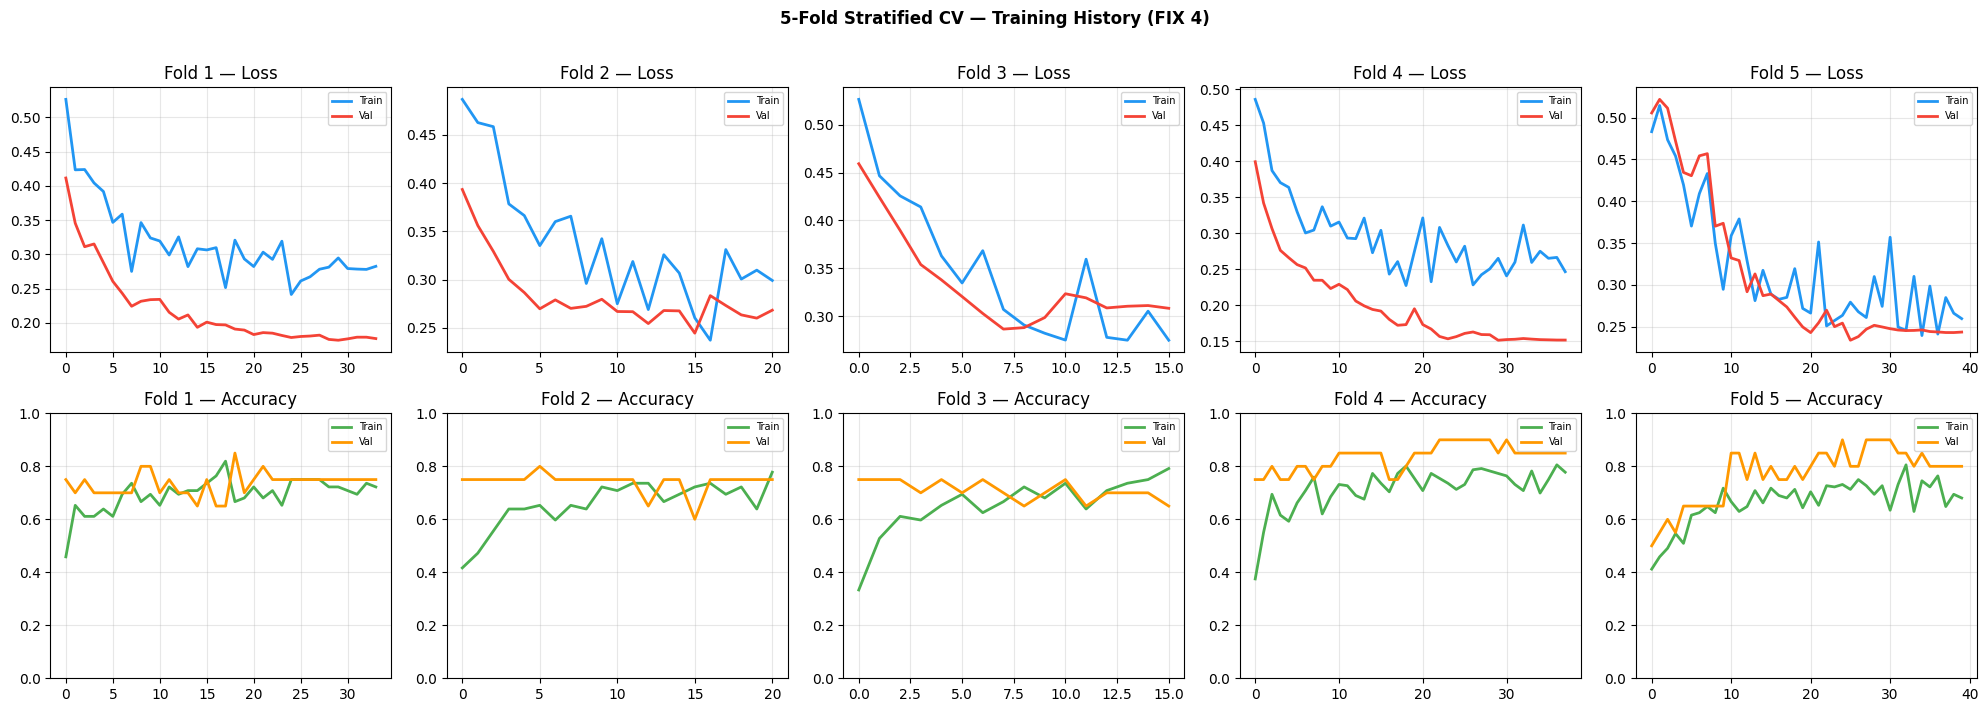


────────────────────────────────────────
  Fold   Best Val Acc
────────────────────────────────────────
     1         0.8500
     2         0.8000
     3         0.7500
     4         0.9000
     5         0.9000
────────────────────────────────────────
  Mean         0.8400


In [41]:
fig, axes = plt.subplots(2, N_FOLDS, figsize=(4*N_FOLDS, 7))
fig.suptitle('5-Fold Stratified CV — Training History (FIX 4)', fontweight='bold', y=1.01)

for col, r in enumerate(fold_results):
    h = r['history']
    ax_loss = axes[0][col] if N_FOLDS > 1 else axes[0]
    ax_acc  = axes[1][col] if N_FOLDS > 1 else axes[1]

    ax_loss.plot(h['loss'],     color='#2196F3', lw=2, label='Train')
    ax_loss.plot(h['val_loss'], color='#F44336', lw=2, label='Val')
    ax_loss.set_title(f"Fold {r['fold']} — Loss")
    ax_loss.legend(fontsize=7); ax_loss.grid(alpha=0.3)

    ax_acc.plot(h['acc'],     color='#4CAF50', lw=2, label='Train')
    ax_acc.plot(h['val_acc'], color='#FF9800', lw=2, label='Val')
    ax_acc.set_title(f"Fold {r['fold']} — Accuracy")
    ax_acc.set_ylim(0, 1); ax_acc.legend(fontsize=7); ax_acc.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# CV Summary table
print(f'\n{"─"*40}')
print(f'{"Fold":>6}  {"Best Val Acc":>13}')
print(f'{"─"*40}')
for r in fold_results:
    print(f'{r["fold"]:>6}  {r["best_val_acc"]:>13.4f}')
print(f'{"─"*40}')
print(f'{"Mean":>6}  {mean_acc:>13.4f}')


## Module 5 Output — Feature Visualisation + t-SNE
(Uses best fold's validation set — FIX 1 benefit)

Valid samples: 17
Classes: {0: 7, 1: 3, 2: 7}


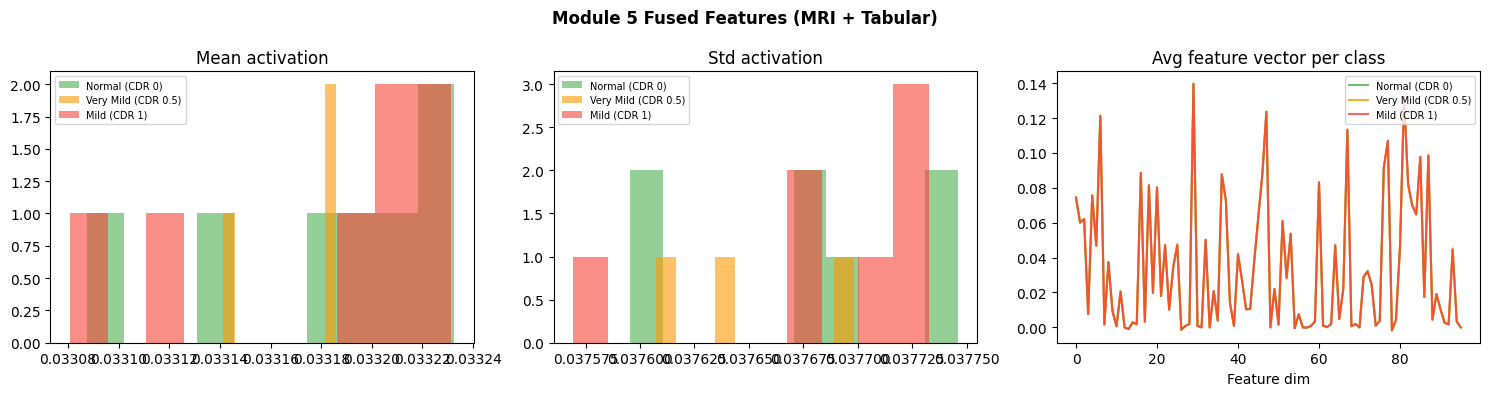

In [52]:
model.load_state_dict(torch.load('/content/AD_model_m5_best.pth', map_location=device))
model.eval()

# Use best fold's val set for all downstream evaluation (FIX 1 + 4)
best_val_loader = DataLoader(
    Subset(full_dataset, best_fold_val_idx),
    batch_size=4, shuffle=False, num_workers=0)

all_feats, all_labels = [], []
with torch.no_grad():
    for mri, hippo, tabular, labels in best_val_loader:
        fused, _, _ = model(mri.to(device), hippo.to(device), tabular.to(device))
        fused       = torch.nan_to_num(fused)
        all_feats.append(fused.cpu())
        all_labels.extend(labels.tolist())

all_feats  = torch.cat(all_feats).numpy()
all_labels = np.array([min(l, 2) for l in all_labels])
mask       = ~np.isnan(all_feats).any(axis=1)
all_feats, all_labels = all_feats[mask], all_labels[mask]
print(f'Valid samples: {len(all_feats)}')
print(f'Classes: {dict(sorted(Counter(all_labels.tolist()).items()))}')

colors  = ['#4CAF50','#FF9800','#F44336','#9C27B0']
CLASS_NAMES = {0:'Normal (CDR 0)', 1:'Very Mild (CDR 0.5)', 2:'Mild (CDR 1)'}
present = sorted(set(all_labels.tolist()))

fig, axes = plt.subplots(1,3,figsize=(15,4))
fig.suptitle('Module 5 Fused Features (MRI + Tabular)', fontweight='bold')
for cls in present:
    m=all_labels==cls; f=all_feats[m]; col=colors[cls]
    axes[0].hist(f.mean(axis=1), bins=10, alpha=0.6, label=CLASS_NAMES[cls], color=col)
    axes[1].hist(f.std(axis=1),  bins=10, alpha=0.6, label=CLASS_NAMES[cls], color=col)
    axes[2].plot(f.mean(axis=0), alpha=0.8, label=CLASS_NAMES[cls], color=col)
axes[0].set_title('Mean activation'); axes[0].legend(fontsize=7)
axes[1].set_title('Std activation');  axes[1].legend(fontsize=7)
axes[2].set_title('Avg feature vector per class')
axes[2].set_xlabel('Feature dim'); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


## FIX 6 — Temperature Scaling (Pooled Out-of-Fold Calibration)
Reloads each fold's *best* checkpoint and evaluates it on that fold's own validation
indices, so every one of the 138 scans gets exactly one true out-of-fold prediction
(no scan is ever scored by a model that trained on it). Temperature `T` is fit on this
pooled set (~138 samples) rather than a single fold's ~28-sample validation set, which
is far less sensitive to 1-2 unlucky misclassifications swinging the estimate.

`T` is only applied downstream if it actually *improves* pooled ECE — otherwise
`T_final = 1.0` (no scaling) is used everywhere else in the notebook.


In [53]:
# ─── FIX 6: Temperature Scaling — fit on pooled out-of-fold predictions ──
class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)

    def forward(self, logits):
        return logits / self.temperature


def fit_temperature_from_logits(logits, labels):
    scaler = TemperatureScaler()
    optimizer = torch.optim.LBFGS([scaler.temperature], lr=0.01, max_iter=50)
    nll = nn.CrossEntropyLoss()

    def closure():
        optimizer.zero_grad()
        loss = nll(scaler(logits), labels)
        loss.backward()
        return loss

    optimizer.step(closure)
    print(f'Fitted temperature (pooled OOF, n={len(labels)}): {scaler.temperature.item():.3f}')
    return scaler.temperature.item()


def compute_ece(df, n_bins=10, label=''):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    correct = (df['true_label'] == df['pred_label']).values
    conf = df['confidence'].values
    print(f'--- {label} ---')
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        mask = (conf > lo) & (conf <= hi)
        if mask.sum() == 0: continue
        bin_acc  = correct[mask].mean()
        bin_conf = conf[mask].mean()
        ece += (mask.sum() / len(df)) * abs(bin_acc - bin_conf)
        print(f'  [{lo:.1f}-{hi:.1f}]  n={mask.sum():3d}  acc={bin_acc:.3f}  avg_conf={bin_conf:.3f}')
    print(f'ECE: {ece:.4f}\n')
    return ece


def logits_to_df(logits, labels, T=1.0):
    probs = F.softmax(logits / T, dim=1)
    preds = probs.argmax(dim=1)
    conf  = probs.max(dim=1).values
    return pd.DataFrame({
        'true_label': labels.numpy(),
        'pred_label': preds.numpy(),
        'confidence': conf.numpy(),
    })


# ── Build pooled out-of-fold logits: each fold's BEST checkpoint scored
#    only on that fold's own (held-out) validation indices ──────────────
oof_logits, oof_labels = [], []
for fr in fold_results:
    f = fr['fold']
    val_idx = fr['val_idx']
    m = ADModel_M5().to(device)
    m.load_state_dict(torch.load(f'/content/AD_model_fold{f}.pth', map_location=device))
    m.eval()
    loader = DataLoader(Subset(full_dataset, val_idx), batch_size=4, shuffle=False, num_workers=0)
    with torch.no_grad():
        for mri, hippo, tabular, labels in loader:
            mri, hippo, tabular = mri.to(device), hippo.to(device), tabular.to(device)
            _, _, cls_logits = m(mri, hippo, tabular)
            oof_logits.append(torch.nan_to_num(cls_logits).cpu())
            oof_labels.append(labels.clamp(max=2))

oof_logits = torch.cat(oof_logits)
oof_labels = torch.cat(oof_labels)
print(f'Pooled OOF predictions: {len(oof_labels)} samples across {len(fold_results)} folds\n')

# ── Fit T on the pooled set, then only keep it if it actually helps ─────
oof_before = logits_to_df(oof_logits, oof_labels, T=1.0)
T = fit_temperature_from_logits(oof_logits, oof_labels)
oof_after = logits_to_df(oof_logits, oof_labels, T=T)

ece_before_oof = compute_ece(oof_before, label='Pooled OOF — Before scaling (T=1.0)')
ece_after_oof  = compute_ece(oof_after,  label=f'Pooled OOF — After scaling (T={T:.3f})')

if ece_after_oof < ece_before_oof:
    print(f'Temperature scaling improves pooled calibration '
          f'({ece_before_oof:.4f} -> {ece_after_oof:.4f}). Using T_final={T:.3f}.')
    T_final = T
else:
    print(f'Temperature scaling does NOT improve pooled calibration '
          f'({ece_before_oof:.4f} -> {ece_after_oof:.4f}). Keeping T_final=1.0 (no scaling).')
    T_final = 1.0


Pooled OOF predictions: 88 samples across 5 folds

Fitted temperature (pooled OOF, n=88): 1.435
--- Pooled OOF — Before scaling (T=1.0) ---
  [0.3-0.4]  n= 19  acc=0.737  avg_conf=0.383
  [0.4-0.5]  n= 27  acc=0.667  avg_conf=0.450
  [0.5-0.6]  n=  5  acc=0.800  avg_conf=0.563
  [0.6-0.7]  n= 12  acc=0.917  avg_conf=0.658
  [0.7-0.8]  n=  8  acc=1.000  avg_conf=0.750
  [0.8-0.9]  n=  2  acc=1.000  avg_conf=0.817
  [0.9-1.0]  n= 15  acc=1.000  avg_conf=0.952
ECE: 0.2266

--- Pooled OOF — After scaling (T=1.435) ---
  [0.3-0.4]  n= 26  acc=0.769  avg_conf=0.374
  [0.4-0.5]  n= 22  acc=0.591  avg_conf=0.434
  [0.5-0.6]  n= 13  acc=0.923  avg_conf=0.553
  [0.6-0.7]  n= 11  acc=1.000  avg_conf=0.641
  [0.7-0.8]  n=  1  acc=1.000  avg_conf=0.708
  [0.8-0.9]  n= 12  acc=1.000  avg_conf=0.862
  [0.9-1.0]  n=  3  acc=1.000  avg_conf=0.904
ECE: 0.2811

Temperature scaling does NOT improve pooled calibration (0.2266 -> 0.2811). Keeping T_final=1.0 (no scaling).


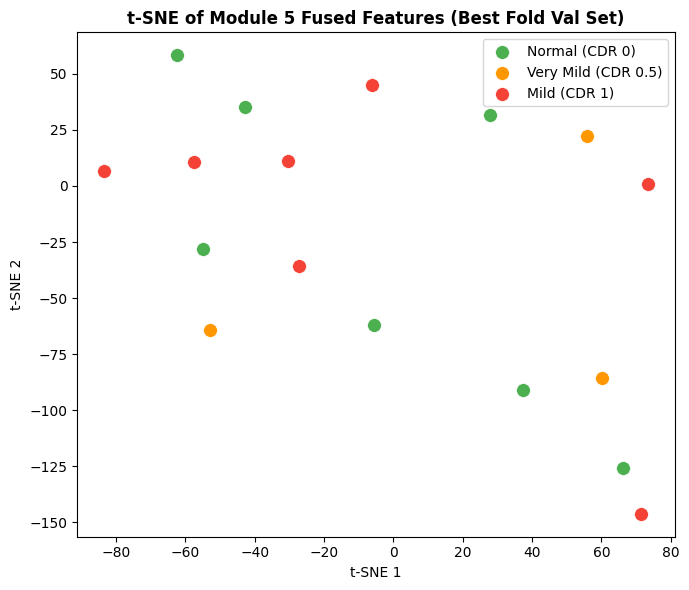

In [54]:
if len(all_feats) >= 10:
    perp = min(5, len(all_feats)-1)
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42, max_iter=1000)
    proj = tsne.fit_transform(StandardScaler().fit_transform(all_feats))
    fig, ax = plt.subplots(figsize=(7,6))
    for cls in present:
        m = all_labels==cls
        ax.scatter(proj[m,0], proj[m,1], label=CLASS_NAMES[cls],
                   s=100, color=colors[cls], edgecolors='white', linewidths=0.5)
    ax.set_title('t-SNE of Module 5 Fused Features (Best Fold Val Set)', fontweight='bold')
    ax.legend(); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
    plt.tight_layout(); plt.show()
else:
    print(f'Only {len(all_feats)} samples — need ≥10 for t-SNE')


## Final Evaluation — Confusion Matrix + Classification Report
(Best fold's val set — unbiased estimate, FIX 1 + 4)

Classification Report (Best Fold Val Set):
                     precision    recall  f1-score   support

     Normal (CDR 0)       0.88      1.00      0.93         7
Very Mild (CDR 0.5)       0.67      0.67      0.67         3
       Mild (CDR 1)       1.00      0.86      0.92         7

           accuracy                           0.88        17
          macro avg       0.85      0.84      0.84        17
       weighted avg       0.89      0.88      0.88        17



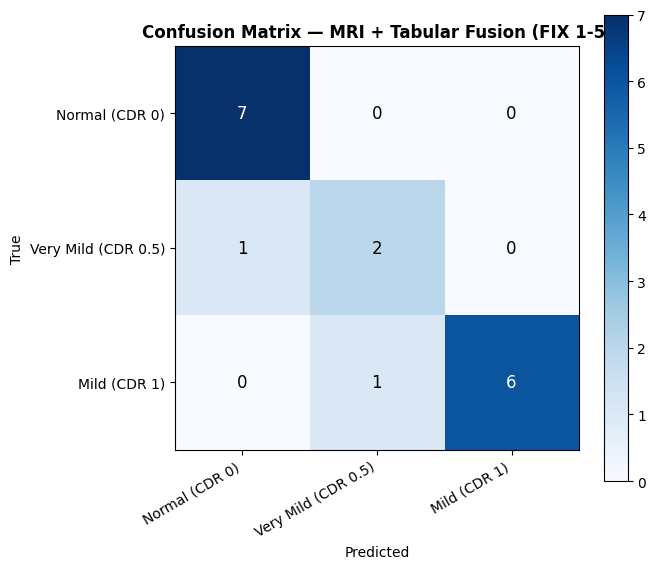

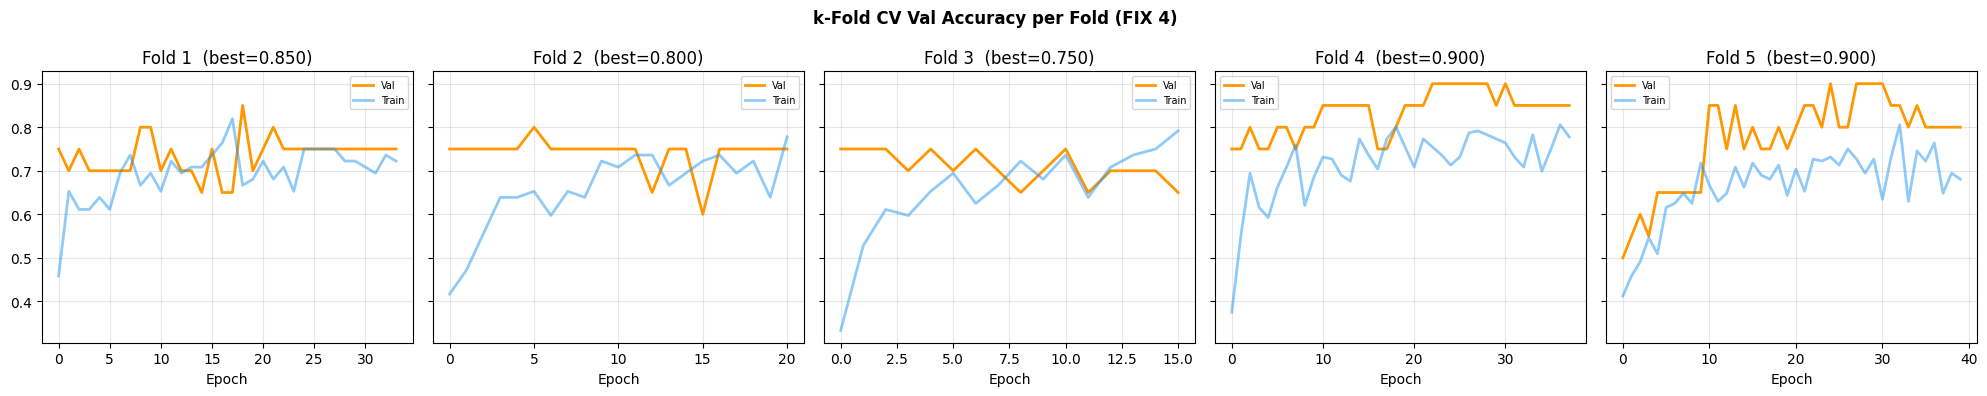


Mean CV Val Acc: 0.8400


In [55]:
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for mri, hippo, tabular, labels in best_val_loader:
        fused, seg_logits, cls_logits = model(mri.to(device), hippo.to(device), tabular.to(device))
        cls_logits = torch.nan_to_num(cls_logits)
        preds      = cls_logits.argmax(dim=1).cpu()
        all_preds.extend(preds.tolist())
        all_true.extend([min(l.item(), 2) for l in labels])

present_cls = sorted(set(all_true))
names_used  = [CLASS_NAMES[c] for c in present_cls]

print('Classification Report (Best Fold Val Set):')
print(classification_report(all_true, all_preds,
      labels=present_cls, target_names=names_used, zero_division=0))

cm  = confusion_matrix(all_true, all_preds, labels=present_cls)
fig, ax = plt.subplots(figsize=(7,6))
im  = ax.imshow(cm, cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks(range(len(present_cls))); ax.set_xticklabels(names_used, rotation=30, ha='right')
ax.set_yticks(range(len(present_cls))); ax.set_yticklabels(names_used)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix — MRI + Tabular Fusion (FIX 1-5)', fontweight='bold')
for r in range(len(present_cls)):
    for c in range(len(present_cls)):
        ax.text(c,r,str(cm[r,c]),ha='center',va='center',fontsize=12,
                color='white' if cm[r,c]>cm.max()/2 else 'black')
plt.tight_layout(); plt.show()

# Cross-validation summary plot
fig, axes = plt.subplots(1, N_FOLDS, figsize=(4*N_FOLDS, 4), sharey=True)
if N_FOLDS == 1: axes = [axes]
fig.suptitle('k-Fold CV Val Accuracy per Fold (FIX 4)', fontweight='bold')
for ax, r in zip(axes, fold_results):
    ax.plot(r['history']['val_acc'], color='#FF9800', lw=2, label='Val')
    ax.plot(r['history']['acc'],     color='#2196F3', lw=2, alpha=0.5, label='Train')
    ax.set_title(f"Fold {r['fold']}  (best={r['best_val_acc']:.3f})")
    ax.set_xlabel('Epoch'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'\nMean CV Val Acc: {mean_acc:.4f}')


# Module 6 & 7 — Feature Fusion/Classification and Output/Visualization

## Module 6 — Feature Fusion and Classification Module
Formalises the HLD Module 6 API on top of the already-trained `ADModel_M5`.
`AttentionFusion` (Module 5) already merges the segmentation-derived local
features with the Swin transformer's global context inside the model's
`forward()`; this section wraps that pipeline into clean inference
functions producing the three HLD data structures: **fused feature
vectors**, **probability distributions**, and **classification outputs**.

In [56]:
# ═══════════════════════════════════════════════════════════════════════
# MODULE 6 — Feature Fusion and Classification
#   Input : shared_feat (Module 3) -> local_feat (Module 4a) +
#           global_feat (Module 4b) -> AttentionFusion (Module 5) ->
#           concat with tabular -> dense layers -> softmax
#   Output: fused feature vectors, probability distributions,
#           classification outputs (Normal / Very Mild / Mild)
# ═══════════════════════════════════════════════════════════════════════

model.load_state_dict(torch.load('/content/AD_model_m5_best.pth', map_location=device))
model.eval()

CLASS_NAMES = {0: 'Normal (CDR 0)', 1: 'Very Mild (CDR 0.5)', 2: 'Mild (CDR 1)'}


@torch.no_grad()
def classify_batch(mri, hippo, tabular):
    """Original (unscaled) confidence — kept for before/after comparison."""
    mri, hippo, tabular = mri.to(device), hippo.to(device), tabular.to(device)
    fused, seg_logits, cls_logits = model(mri, hippo, tabular)
    cls_logits = torch.nan_to_num(cls_logits)
    probs = F.softmax(cls_logits, dim=1)
    pred_labels = probs.argmax(dim=1)
    confidence = probs.max(dim=1).values
    return fused.cpu(), probs.cpu(), pred_labels.cpu(), confidence.cpu()


@torch.no_grad()
def classify_batch_scaled(mri, hippo, tabular):
    """Temperature-scaled confidence."""
    mri, hippo, tabular = mri.to(device), hippo.to(device), tabular.to(device)
    fused, seg_logits, cls_logits = model(mri, hippo, tabular)
    cls_logits = torch.nan_to_num(cls_logits) / T
    probs = F.softmax(cls_logits, dim=1)
    pred_labels = probs.argmax(dim=1)
    confidence = probs.max(dim=1).values
    return fused.cpu(), probs.cpu(), pred_labels.cpu(), confidence.cpu()


def classify_dataset(loader, fn=classify_batch):
    """Runs Module 6 over a full DataLoader and returns a results table."""
    records = []
    for mri, hippo, tabular, labels in loader:
        fused, probs, preds, conf = fn(mri, hippo, tabular)
        true = labels.clamp(max=2)
        for i in range(len(preds)):
            records.append({
                'true_label':     int(true[i]),
                'pred_label':     int(preds[i]),
                'confidence':     float(conf[i]),
                'prob_normal':    float(probs[i, 0]),
                'prob_very_mild': float(probs[i, 1]),
                'prob_mild':      float(probs[i, 2]),
                'fused_vector':   fused[i].numpy(),
            })
    return pd.DataFrame(records)


results_df     = classify_dataset(best_val_loader, fn=classify_batch)
results_scaled = classify_dataset(best_val_loader, fn=classify_batch_scaled)

print(f'Module 6 — classified {len(results_df)} samples (best-fold val set)')
results_df[['true_label', 'pred_label', 'confidence',
            'prob_normal', 'prob_very_mild', 'prob_mild']].head(10)


Module 6 — classified 17 samples (best-fold val set)


,true_label,pred_label,confidence,prob_normal,prob_very_mild,prob_mild
0,2,2,0.962781,0.009865,0.027354,0.962781
1,0,0,0.483252,0.483252,0.423651,0.093097
2,2,2,0.965941,0.009613,0.024445,0.965941
3,1,0,0.681392,0.681392,0.278092,0.040517
4,2,2,0.970460,0.008698,0.020841,0.970460
5,2,1,0.427951,0.295070,0.427951,0.276979
6,0,0,0.698537,0.698537,0.263593,0.037871
7,2,2,0.443901,0.178564,0.377536,0.443901
8,0,0,0.697256,0.697256,0.264751,0.037993
9,0,0,0.651090,0.651090,0.274330,0.074580


### Module 6 Output — Confidence and Probability-Distribution Diagnostics
Sanity checks that go with the classification output: how confident the
model is when it's right vs. wrong, and how the predicted probability
distribution shifts with the true disease stage.

--- Best-fold val — Before scaling (T=1.0) ---
  [0.4-0.5]  n=  4  acc=0.750  avg_conf=0.444
  [0.5-0.6]  n=  1  acc=1.000  avg_conf=0.568
  [0.6-0.7]  n=  6  acc=0.833  avg_conf=0.671
  [0.8-0.9]  n=  1  acc=1.000  avg_conf=0.808
  [0.9-1.0]  n=  5  acc=1.000  avg_conf=0.968
ECE: 0.1755

--- Best-fold val — After scaling (T_final=1.000) ---
  [0.3-0.4]  n=  2  acc=0.500  avg_conf=0.399
  [0.4-0.5]  n=  2  acc=1.000  avg_conf=0.431
  [0.5-0.6]  n=  5  acc=0.800  avg_conf=0.559
  [0.6-0.7]  n=  3  acc=1.000  avg_conf=0.639
  [0.8-0.9]  n=  2  acc=1.000  avg_conf=0.892
  [0.9-1.0]  n=  3  acc=1.000  avg_conf=0.904
ECE: 0.2431



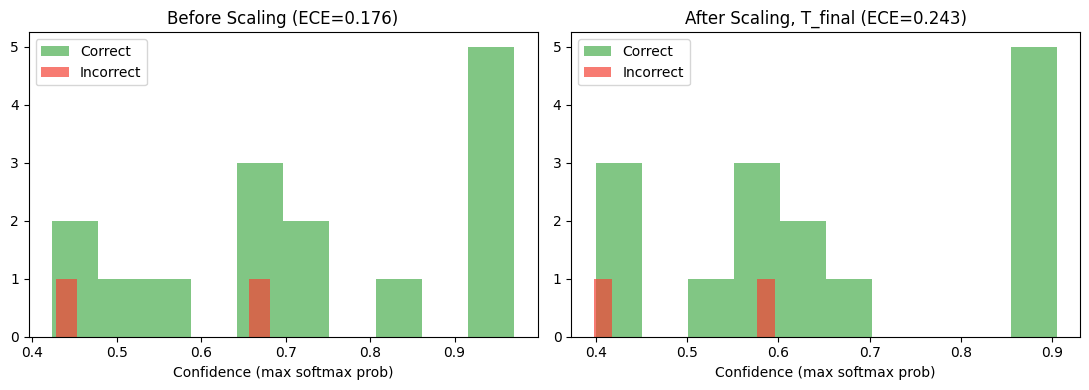

In [57]:
# Note: T_final (decided from pooled OOF ECE in FIX 6) is the number that
# actually gets used everywhere downstream. This plot is a reference view
# on just the best fold's 28-sample val set, using the already-decided T_final —
# it is not what T_final was chosen from.
ece_before = compute_ece(results_df,     label='Best-fold val — Before scaling (T=1.0)')
ece_after  = compute_ece(results_scaled, label=f'Best-fold val — After scaling (T_final={T_final:.3f})')

correct = results_df['true_label'] == results_df['pred_label']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(results_df.loc[correct, 'confidence'],  bins=10, alpha=0.7, color='#4CAF50', label='Correct')
axes[0].hist(results_df.loc[~correct, 'confidence'], bins=10, alpha=0.7, color='#F44336', label='Incorrect')
axes[0].set_title(f'Before Scaling (ECE={ece_before:.3f})')
axes[0].set_xlabel('Confidence (max softmax prob)')
axes[0].legend()

axes[1].hist(results_scaled.loc[correct, 'confidence'],  bins=10, alpha=0.7, color='#4CAF50', label='Correct')
axes[1].hist(results_scaled.loc[~correct, 'confidence'], bins=10, alpha=0.7, color='#F44336', label='Incorrect')
axes[1].set_title(f'After Scaling, T_final (ECE={ece_after:.3f})')
axes[1].set_xlabel('Confidence (max softmax prob)')
axes[1].legend()

plt.tight_layout()
plt.show()


## Module 7 — Output and Visualization Module
This was the main gap flagged in the HLD coverage review — no Grad-CAM or
attention heatmaps existed. This section adds both, using the model's
*already-trained* weights (no retraining needed):

- **Grad-CAM 3D** on the last conv block of the Module 3 shared encoder,
  showing which brain voxels most influenced the classification score.
- **Attention heatmap** extracted directly from the Module 4b Swin
  cross-attention weights (fine hippocampal windows attending to coarse
  whole-brain windows), showing where the transformer's global context
  is focusing.
- A combined **diagnostic report** per patient: predicted stage +
  confidence + both overlays + probability bar chart — matching the HLD
  Step 7 output ("Predicted disease stage" + "Attention maps highlighting
  important brain regions").

In [58]:
# ═══════════════════════════════════════════════════════════════════════
# MODULE 7a — Grad-CAM (Gradient-weighted Class Activation Mapping)
# ═══════════════════════════════════════════════════════════════════════

class GradCAM3D:
    """
    Hooks the last conv block of the Module 3 shared encoder and backs out
    a voxel-level heatmap of which regions drove the predicted class.
    """
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def generate(self, mri, hippo, tabular, target_class=None):
        self.model.eval()
        mri = mri.clone().to(device).requires_grad_(True)
        hippo = hippo.to(device)
        tabular = tabular.to(device)

        fused, seg_logits, cls_logits = self.model(mri, hippo, tabular)
        cls_logits = torch.nan_to_num(cls_logits)
        if target_class is None:
            target_class = cls_logits.argmax(dim=1)
        target_class = target_class.to(device)

        self.model.zero_grad()
        score = cls_logits.gather(1, target_class.view(-1, 1)).sum()
        score.backward()

        weights = self.gradients.mean(dim=(2, 3, 4), keepdim=True)            # [B,C,1,1,1]
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))   # [B,1,d,h,w]
        cam = F.interpolate(cam, size=mri.shape[2:], mode='trilinear', align_corners=False)
        cam = cam.squeeze(1).detach().cpu().numpy()

        for i in range(cam.shape[0]):
            c = cam[i]
            cmin, cmax = c.min(), c.max()
            cam[i] = (c - cmin) / (cmax - cmin + 1e-8)

        probs = F.softmax(cls_logits / T_final, dim=1).detach().cpu().numpy()   # temperature-scaled
        return cam, target_class.cpu().numpy(), probs


grad_cam = GradCAM3D(model, model.shared_encoder.block3)
print('Module 7a ready — Grad-CAM hooked to shared_encoder.block3 '
      '(last conv block of the Module 3 backbone, 96 channels @ 16x16x16)')


Module 7a ready — Grad-CAM hooked to shared_encoder.block3 (last conv block of the Module 3 backbone, 96 channels @ 16x16x16)


In [59]:
# ═══════════════════════════════════════════════════════════════════════
# MODULE 7b — Attention Heatmap (from Module 4b Swin cross-attention)
# ═══════════════════════════════════════════════════════════════════════

def get_attention_heatmap(model, mri, hippo, tabular):
    model.eval()
    with torch.no_grad():
        mri, hippo, tabular = mri.to(device), hippo.to(device), tabular.to(device)
        x_in = torch.cat([mri, hippo], dim=1)          # match ADModel_M5.forward
        shared_feat = model.shared_encoder(x_in)        # use x_in, not mri
        swin = model.swin_transformer

        B = shared_feat.size(0)

        x = swin.proj(shared_feat)
        fine_tokens, (_, nD, nH, nW) = swin.patch_fine(x)
        for blk in swin.swin_fine:
            fine_tokens = blk(fine_tokens)
        fine_global = fine_tokens.mean(dim=1, keepdim=True).view(B, nD * nH * nW, -1)

        coarse_tokens, (_, cD, cH, cW) = swin.patch_coarse(x)
        for blk in swin.swin_coarse:
            coarse_tokens = blk(coarse_tokens)
        coarse_global = coarse_tokens.mean(dim=1).view(B, cD * cH * cW, -1)

        _, attn_w = swin.cross_attn(fine_global, coarse_global, coarse_global,
                                     need_weights=True, average_attn_weights=True)
        # attn_w: [B, 64 fine windows, 8 coarse windows]
        # salience = how strongly each fine (hippocampal-scale) window focuses
        # on any single coarse (whole-brain-scale) window
        salience = attn_w.max(dim=-1).values.view(B, nD, nH, nW)              # [B,4,4,4]
        heatmap = F.interpolate(salience.unsqueeze(1), size=mri.shape[2:],
                                 mode='trilinear', align_corners=False).squeeze(1)
        heatmap = heatmap.cpu().numpy()

    for i in range(heatmap.shape[0]):
        h = heatmap[i]
        hmin, hmax = h.min(), h.max()
        heatmap[i] = (h - hmin) / (hmax - hmin + 1e-8)
    return heatmap


print('Module 7b ready — attention heatmap extracted from Module 4b cross-attention')


Module 7b ready — attention heatmap extracted from Module 4b cross-attention


Highest-confidence sample: dataset index 80  (confidence = 0.905)


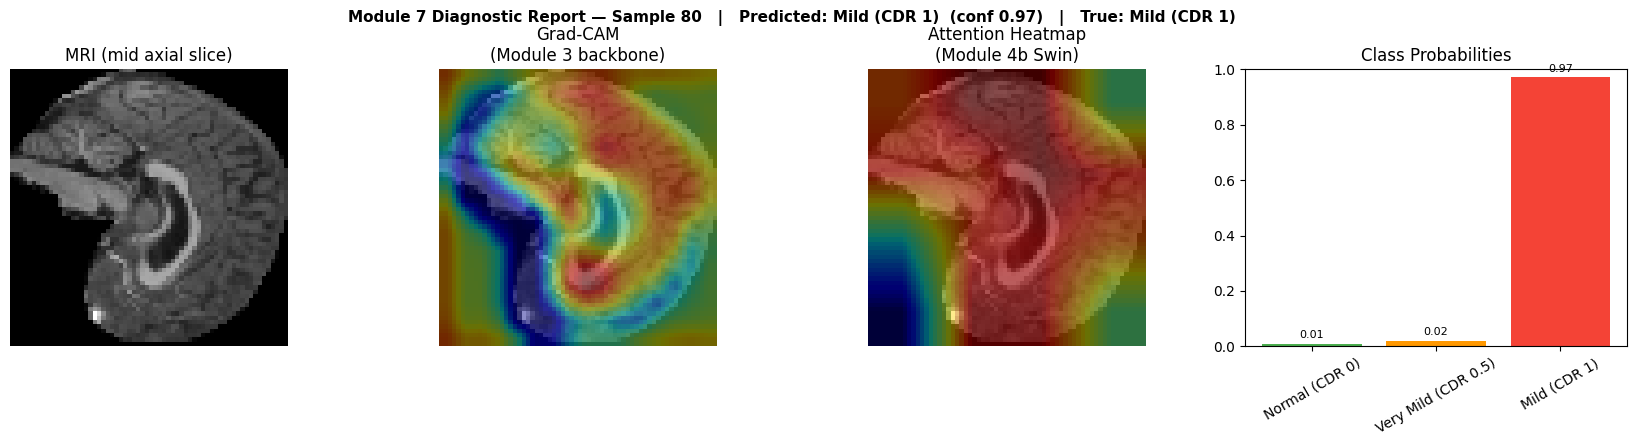

Predicted disease stage : Mild (CDR 1)
Confidence              : 97.1%
Ground truth             : Mild (CDR 1)


{'pred_label': 2,
 'true_label': 2,
 'confidence': 0.9709242582321167,
 'probs': array([0.00857964, 0.02049598, 0.97092426], dtype=float32)}

In [60]:
# ═══════════════════════════════════════════════════════════════════════
# MODULE 7c — Combined Diagnostic Report (HLD Step 7: Output & Interpretation)
# ═══════════════════════════════════════════════════════════════════════

def generate_diagnostic_report(sample_idx, dataset=full_dataset):
    """
    Produces the final per-patient output: predicted disease stage +
    confidence + Grad-CAM overlay + attention overlay + probability bars.
    """
    mri, hippo, tabular, true_label = dataset[sample_idx]
    mri_b = mri.unsqueeze(0)
    tab_b = tabular.unsqueeze(0)

    cam, pred_cls, probs = grad_cam.generate(mri_b, hippo.unsqueeze(0), tab_b)
    attn_map = get_attention_heatmap(model, mri_b, hippo.unsqueeze(0), tab_b)

    pred_label = int(pred_cls[0])
    true_label = min(int(true_label), 2)
    confidence = float(probs[0, pred_label])

    mri_np = mri.squeeze(0).numpy()
    mid = mri_np.shape[0] // 2
    mri_slice = mri_np[mid]
    cam_slice = cam[0, mid]
    attn_slice = attn_map[0, mid]

    fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
    fig.suptitle(
        f'Module 7 Diagnostic Report — Sample {sample_idx}   |   '
        f'Predicted: {CLASS_NAMES[pred_label]}  (conf {confidence:.2f})   |   '
        f'True: {CLASS_NAMES[true_label]}',
        fontweight='bold', fontsize=11)

    axes[0].imshow(mri_slice, cmap='gray')
    axes[0].set_title('MRI (mid axial slice)')
    axes[0].axis('off')

    axes[1].imshow(mri_slice, cmap='gray')
    axes[1].imshow(cam_slice, cmap='jet', alpha=0.45)
    axes[1].set_title('Grad-CAM\n(Module 3 backbone)')
    axes[1].axis('off')

    axes[2].imshow(mri_slice, cmap='gray')
    axes[2].imshow(attn_slice, cmap='jet', alpha=0.45)
    axes[2].set_title('Attention Heatmap\n(Module 4b Swin)')
    axes[2].axis('off')

    bar_colors = ['#4CAF50', '#FF9800', '#F44336']
    axes[3].bar(list(CLASS_NAMES.values()), probs[0], color=bar_colors)
    axes[3].set_ylim(0, 1)
    axes[3].set_title('Class Probabilities')
    axes[3].tick_params(axis='x', rotation=30)
    for i, p in enumerate(probs[0]):
        axes[3].text(i, p + 0.02, f'{p:.2f}', ha='center', fontsize=8)

    plt.tight_layout()
    plt.show()

    print(f'Predicted disease stage : {CLASS_NAMES[pred_label]}')
    print(f'Confidence              : {confidence:.1%}')
    print(f'Ground truth             : {CLASS_NAMES[true_label]}')
    return {'pred_label': pred_label, 'true_label': true_label,
            'confidence': confidence, 'probs': probs[0]}


# Show only the single highest-confidence diagnostic report
best_row_pos = results_scaled['confidence'].idxmax()
best_idx = best_fold_val_idx[best_row_pos]
print(f'Highest-confidence sample: dataset index {best_idx}  '
      f'(confidence = {results_scaled.loc[best_row_pos, "confidence"]:.3f})')

generate_diagnostic_report(best_idx)


## Save All Models to Google Drive

In [61]:
import shutil
DRIVE_OUT = '/content/drive/MyDrive/alzheimer_results'
os.makedirs(DRIVE_OUT, exist_ok=True)

for f in ['hippocampus_unet.pth',
          'hippocampus_unet_finetuned.pth',
          'AD_model_m5_best.pth']:
    src = f'/content/{f}'
    if os.path.exists(src):
        shutil.copy(src, os.path.join(DRIVE_OUT, f))
        print(f'Saved: {DRIVE_OUT}/{f}')

print('\n✔ All models saved to Google Drive')

Saved: /content/drive/MyDrive/alzheimer_results/hippocampus_unet.pth
Saved: /content/drive/MyDrive/alzheimer_results/AD_model_m5_best.pth

✔ All models saved to Google Drive
